# Builds off of TE_compositing.ipynb, by making cyclone-relative composites at the DEVELOPMENT stages

In [31]:
### Importing necessary packages
import pandas as pd
import os
from pathlib import Path
import re
import warnings

#warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", module="cartopy")

import matplotlib 
import matplotlib.pyplot as plt
import matplotlib.colors as col
from matplotlib.gridspec import GridSpec
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.ticker import MaxNLocator
import matplotlib.contour as mcontour
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable

import cmocean
import cartopy.feature as cfeature
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import numpy as np
import seaborn as sns
import xarray as xr

from scipy.stats import permutation_test
from scipy.optimize import linear_sum_assignment


## custom packages:
#from download_era5_composite import timestamps_from_etc_summary, build_date_groups, download, OUT_DIR

## Copied Functions from TE_compositing.ipynb (permutation test code, parsing nodefiles, making nodes_df and picks_df)

In [32]:
## Permutation significance test for OC vs NOC composite differences,
## following Tochimoto & Niino (2016, MWR). Reusable across variables.
def perm_test_diff_means(oc_stack, noc_stack, n_resamples=10000, seed=1, min_count=10):
    """Grid-point permutation test on the OC-NOC difference of means.

    Pools the two per-cyclone snapshot stacks (snap_<var> from the composite
    files), then on each iteration randomly relabels ``n_oc`` of the pooled
    cyclones as pseudo-OC and recomputes the difference field. Whole cyclones
    are resampled together (one shared permutation for the entire grid), so the
    spatial covariance of the fields is preserved. This is the "means of two
    distributions are different" test TN2016 cite from Efron & Tibshirani (1993).

    NaNs -- grid points a cyclone's box does not cover, because its center sat
    near the edge of the ERA5 download domain -- are handled with nan-aware
    means: each grid point uses only the cyclones that actually cover it. The
    fast update D = S1/C1 - (T-S1)/(Ct-C1) sums only the n_oc sampled rows per
    iteration (~4 s at n_resamples=5000 for 114 vs 449).

    Parameters
    ----------
    oc_stack, noc_stack : (n, ny, nx) arrays, in the SAME units you plot.
    n_resamples : number of label permutations (bump to 10000 for a final fig).
    seed        : RNG seed for reproducibility.
    min_count   : grid points where either group has fewer than this many
                  contributing cyclones are masked (p = NaN); too poorly
                  sampled to test.

    Returns
    -------
    diff_obs : (ny, nx) observed OC-NOC difference of means (nan-aware).
    pval     : (ny, nx) two-sided permutation p-value, (count + 1)/(K + 1),
               with undersampled points set to NaN.
    """
    n_oc = oc_stack.shape[0]
    A = np.concatenate([oc_stack, noc_stack], axis=0).astype(np.float64)
    N, ny, nx = A.shape
    A = A.reshape(N, -1)

    valid = ~np.isnan(A)
    Az = np.where(valid, A, 0.0)      # values, NaN -> 0
    M  = valid.astype(np.float64)     # 1 where a cyclone covers this grid point
    T  = Az.sum(0)                    # total value sum per grid point
    Ct = M.sum(0)                     # total contributing count per grid point

    def diff(idx):
        S1 = Az[idx].sum(0); C1 = M[idx].sum(0)      # pseudo-OC
        S2 = T - S1;         C2 = Ct - C1            # pseudo-NOC
        with np.errstate(invalid="ignore", divide="ignore"):
            return S1 / C1 - S2 / C2

    diff_obs = diff(np.arange(n_oc))                 # first n_oc rows ARE the OC
    absobs = np.abs(diff_obs)

    rng = np.random.default_rng(seed)
    count = np.zeros(A.shape[1])
    for _ in range(n_resamples):
        idx = rng.choice(N, size=n_oc, replace=False)
        with np.errstate(invalid="ignore"):
            count += np.abs(diff(idx)) >= absobs

    pval = (count + 1) / (n_resamples + 1)

    C1o = M[:n_oc].sum(0); C2o = Ct - C1o            # observed contributing counts
    poor = (C1o < min_count) | (C2o < min_count)
    diff_obs = diff_obs.reshape(ny, nx)
    pval = pval.reshape(ny, nx)
    pval[poor.reshape(ny, nx)] = np.nan
    return diff_obs, pval


def bh_fdr(pval, alpha_fdr=0.10):
    """Benjamini-Hochberg false-discovery-rate control on a p-value field.

    perm_test_diff_means tests every grid point independently, so at raw
    p < 0.05 roughly 5% of the ~thousands of points would appear "significant"
    by chance alone (Wilks 2016, BAMS). BH-FDR instead finds a single p
    threshold p* such that declaring all points with p <= p* significant keeps
    the EXPECTED fraction of false positives among them at or below alpha_fdr.
    NaN points (undersampled, already masked by perm_test_diff_means) are
    excluded from the procedure.

    Procedure: sort the m valid p-values ascending p(1)..p(m); find the largest
    k with p(k) <= (k/m)*alpha_fdr; the threshold is p* = p(k).

    Returns
    -------
    sig      : bool array, same shape as pval, True where p <= p* (field-
               significant). All False if nothing survives.
    p_thresh : the BH threshold p* (np.nan if nothing is significant).
    """
    p = pval.ravel()
    ok = ~np.isnan(p)
    pv = np.sort(p[ok])                       # ascending valid p-values
    m = pv.size
    if m == 0:
        return np.zeros(pval.shape, dtype=bool), np.nan
    below = pv <= (np.arange(1, m + 1) / m) * alpha_fdr
    if not below.any():
        return np.zeros(pval.shape, dtype=bool), np.nan
    p_thresh = pv[np.max(np.nonzero(below)[0])]   # p at the largest passing k
    sig = (pval <= p_thresh)                  # NaN <= x is False -> stays out
    return sig, p_thresh

def mean_diff(a, b):
    return np.mean(a) - np.mean(b)


# def plot_sig_panel(ax, x, y, pval, diff_obs, sig_fdr, diff_fmt="%.0f", p_thresh=None):
#     """OC-NOC significance panel. Shade the permutation p-value ONLY where it
#     survives FDR control (everything else left white), and overlay the OC-NOC
#     difference itself as labeled black contours. Returns the filled-contour
#     handle so the caller can attach a colorbar."""
#     p_show = np.where(sig_fdr, pval, np.nan)       # only FDR-significant points
#     p_levels = [0.0, 0.01, 0.05, 0.1]
#     p_colors = ["#7f0000", "#d7301f", "#fdae61"]   # p<0.01, 0.01-0.05, 0.05-0.1
#     cfp = ax.contourf(x, y, p_show, levels=p_levels, colors="#d7301f", extend="neither", alpha=0.7 )
#     dmax = np.nanmax(np.abs(diff_obs))
#     d_levels = MaxNLocator(nbins=10, symmetric=True).tick_values(-dmax, dmax)
#     d_levels = d_levels[d_levels != 0]             # drop the zero contour
#     cs = ax.contour(x, y, diff_obs, levels=d_levels, colors="k", linewidths=0.7)
#     ax.clabel(cs, inline=True, fontsize=7, fmt=diff_fmt)
#     ax.plot(0, 0, "kx", markersize=8, markeredgewidth=1.5)
#     ax.set_xlim(-25, 25); ax.set_ylim(-25, 25); ax.grid(True)
#     ax.set_xlabel("Degrees from center (E +)", fontsize=9)
#     return cfp

SIG_COLOR = "#d7301f"
SIG_ALPHA = 0.55

def plot_sig_panel(ax, x, y, pval, diff_obs, sig_fdr, diff_fmt="%.1f", nbins=10):
    """OC-NOC panel: single-colour FDR-significant mask + Δ contours everywhere
    the test ran (significant or not)."""
    ## BH-FDR yields ONE threshold p*, so significance is binary -- a single
    ## shade. (The old 0.01/0.05/0.1 bands showed raw-p gradient among already-
    ## significant points; with p* < 0.01 here the upper two bands are empty.)
    ax.contourf(x, y, sig_fdr.astype(float), levels=[0.5, 1.5],
                colors=[SIG_COLOR], alpha=SIG_ALPHA)

    ## Contour every point that was TESTED, not just the significant ones.
    ## perm_test_diff_means NaNs `pval` where fewer than min_count cyclones
    ## cover a point but leaves `diff_obs` populated there; those domain-corner
    ## values would otherwise set dmax and make the interval far too coarse.
    diff_plot = np.where(np.isfinite(pval), diff_obs, np.nan)
    dmax = np.nanmax(np.abs(diff_plot))
    d_levels = MaxNLocator(nbins=nbins, symmetric=True).tick_values(-dmax, dmax)
    d_levels = d_levels[d_levels != 0]
    cs = ax.contour(x, y, diff_plot, levels=d_levels, colors="k", linewidths=0.7)
    ax.clabel(cs, inline=True, fontsize=7, fmt=diff_fmt)

    ax.plot(0, 0, "kx", markersize=8, markeredgewidth=1.5)
    ax.set_xlim(-25, 25); ax.set_ylim(-25, 25); ax.grid(True)
    ax.set_xlabel("Degrees from center (E +)", fontsize=9)
    return cs


def add_sig_colorbar(fig, ax, p_thresh, alpha_fdr=0.05, **kw):
    """Single-swatch colorbar for the FDR mask, labelled with the BH threshold.

    Built from a standalone ScalarMappable rather than the contourf handle: a
    boolean field gives a degenerate mappable, and when nothing is significant
    contourf produces no filled region at all, so a handle-derived colorbar
    comes out blank or raises.
    """
    cmap = ListedColormap([SIG_COLOR])
    sm = ScalarMappable(cmap=cmap, norm=BoundaryNorm([0, 1], cmap.N))
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, orientation="horizontal", ticks=[0.5], **kw)
    label = ("none significant" if not np.isfinite(p_thresh)
             else f"p $\\leq$ {p_thresh:.4f}")
    cb.ax.set_xticklabels([label])
    cb.solids.set_alpha(SIG_ALPHA)
    cb.set_label(f"FDR-significant ($\\alpha$={alpha_fdr})", fontsize=10)
    return cb

## full 1995-2025 summaries 
etc_summary = pd.read_csv('../data/etc_summary_final.csv')
nodes_with_reports = pd.read_csv('../data/nodes_with_reports_final.csv')
core_summary = pd.read_csv('../data/kde_core_summary.csv')

MASTER_NODEFILE = "/data1/lepique/TempestExtremes/tracks/tracks_hourly_1995_2025.txt"  

## CONFIG
REFERENCE = "min_msl" ## time to center the composite on (can use "max_reports")
COL_TRACKID = "track_id"
COL_NREPORTS = "n_reports"
COL_NCORESKEPT = "n_cores_kept"
COL_TIMEMAXREP = "time_max_reports"
COL_TIMEMSL = "time_min_msl"
REF_TIME_COL = COL_TIMEMSL if REFERENCE == "min_msl" else COL_TIMEMAXREP


## node data columns AFTER the two grid indices:
NODE_DATA_COLS = ["lon", "lat", "msl", "phis"]

## OC / NOC split: a cyclone is an "outbreak cyclone" if it has at least
## OUTBREAK_MIN_CORES kept cores (n_cores_kept >= OUTBREAK_MIN_CORES). NOC =
## fewer than that. Together these partition every in-season cyclone.
## (Earlier this was based on n_reports > 0.)
OUTBREAK_MIN_CORES = 1

## DJFM season for the full 1996-2025 run. December is in-season and is attached
## to the FOLLOWING year's JFM (e.g. Dec 2019 -> season 2020), via season_year().
MONTHS = (12, 1, 2, 3)

def season_year(ts):
    """DJFM season label: December belongs to the following year's JFM season."""
    ts = pd.Timestamp(ts)
    return ts.year + 1 if ts.month == 12 else ts.year

OUT_OC = "data/outbreak_cyclones_min_msl_cores_filtered.txt"
OUT_NOC = "data/nonoutbreak_cyclones_min_msl_cores_filtered.txt"

## ERA5 domain [N, W, S, E] -- kept in sync with download_era5_composite.py,
## which holds the authoritative ERA5 download config (variables, levels, the
## 9 min-MSL +/- offset reference times). Used here only for the southern-
## boundary check in select_reference_nodes.
ERA5_AREA = [70, -140, -10, -50]

## Composite-domain filter. A cyclone is kept only if its reference node lies
## inside this box, so the plotted +/-25 deg composite window stays largely
## inside the ERA5 download domain. Without it the nodefiles are GLOBAL: OC
## centers run from 175 W to 178 E and up to 86 N, and cyclones far outside the
## domain contribute mostly-NaN snapshots that still count toward n.
## [lon_min, lon_max, lat_min, lat_max], degrees east in -180..180.
CONUS_BOX = [-125.0, -65.0, 25.0, 50.0]
RESTRICT_TO_BOX = True


In [33]:
## Parse nodefile 
def parse_nodefile(path, data_cols):
    """
    Parse TE StitchNodes nodefile. track_id is 1-indexed (first block = 1) to
    match etc_summary. Datetime build is vectorized so it scales to the full
    1996-2025 record.
    """

    rows = []
    with open(path) as f:
        lines = [ln.rstrip("\n") for ln in f]

    i = 0
    tid = 0
    n_data = len(data_cols)
    while i < len(lines):
        parts = lines[i].split()
        if not parts:
            i += 1
            continue
        if parts[0] == "start":
            tid +=1
            n_steps = int(parts[1])
            for k in range(1, n_steps + 1):
                np_ = lines[i+k].split()
                grid_i, grid_j = int(np_[0]), int(np_[1])
                data_vals = np_[2:2 + n_data]
                yyyy, mm, dd, off = np_[2 + n_data:2 + n_data + 4]
                row = {
                    "track_id": float(tid),
                    "grid_i": grid_i, "grid_j": grid_j,
                    "year": int(yyyy), "month": int(mm),
                    "day": int(dd), "offset": off,
                }
                for c, v in zip(data_cols, data_vals):
                    row[c] = float(v)
                rows.append(row)
            i += n_steps + 1
        else:
            i +=1
    
    df = pd.DataFrame(rows)
    ## "offset" is the hour-of-day field; build tz-aware UTC datetimes vectorized
    df["datetime"] = (
        pd.to_datetime(dict(year=df["year"], month=df["month"], day=df["day"]),
                       utc=True)
        + pd.to_timedelta(df["offset"].astype(float), unit="h")
    )

    return df

In [34]:
## label OC/NOC, pick reference node
def select_reference_nodes(nodes_df, etc_summary, ref_time_col):
    es = etc_summary[[COL_TRACKID, COL_NREPORTS, COL_NCORESKEPT, ref_time_col]].copy()
    es[ref_time_col] = pd.to_datetime(es[ref_time_col], utc=True)
    es = es.dropna(subset=[ref_time_col])              ## need a reference time
    es = es[es[ref_time_col].dt.month.isin(MONTHS)]    ## DJFM only (December in-season)
    es["is_oc"] = es[COL_NCORESKEPT] >= OUTBREAK_MIN_CORES  ## >=1 kept core -> outbreak; else NOC
    es["season_year"] = es[ref_time_col].apply(season_year)   ## Dec -> following JFM

    ## vectorized nearest-node pick (scales to the full 1996-2025 record)
    merged = nodes_df.merge(
        es[[COL_TRACKID, ref_time_col, COL_NREPORTS, COL_NCORESKEPT, "is_oc", "season_year"]],
        on=COL_TRACKID, how="inner",
    )
    merged["dt_diff"] = (merged["datetime"] - merged[ref_time_col]).abs()
    idx = merged.groupby(COL_TRACKID)["dt_diff"].idxmin()
    picks_df = merged.loc[idx].sort_values(COL_TRACKID).reset_index(drop=True)

    ## tracks requested (in-season, with a reference time) but absent from the nodefile
    missing = sorted(set(es[COL_TRACKID]) - set(picks_df[COL_TRACKID]))
    if missing:
        head = ", ".join(f"{m:.0f}" for m in missing[:10])
        print(f"WARNING: {len(missing)} track(s) not in nodefile: {head}"
              f"{' ...' if len(missing) > 10 else ''}")

    ## flag any pick whose nearest node is > 1 h from the reference time
    far = picks_df[picks_df["dt_diff"] > pd.Timedelta(hours=1)]
    for _, n in far.iterrows():
        print(f"NOTE: track {n[COL_TRACKID]:.0f} nearest node "
              f"{n['dt_diff']} from {ref_time_col}")

    ## restrict to cyclones whose reference node lies inside CONUS_BOX. Done
    ## BEFORE the counts below so the printed OC/NOC totals match the nodefiles
    ## that actually get written.
    if RESTRICT_TO_BOX:
        lon180 = ((picks_df["lon"] + 180) % 360) - 180
        inbox = (lon180.between(CONUS_BOX[0], CONUS_BOX[1])
                 & picks_df["lat"].between(CONUS_BOX[2], CONUS_BOX[3]))
        dropped = picks_df[~inbox]
        if len(dropped):
            n_oc_d = int(dropped["is_oc"].sum())
            print(f"\n  BOX FILTER: dropped {len(dropped)} cyclone(s) with a "
                  f"reference node outside {CONUS_BOX} "
                  f"({n_oc_d} OC / {len(dropped) - n_oc_d} NOC)")
        picks_df = picks_df[inbox].reset_index(drop=True)

    print(f"\n  DJFM seasons : {picks_df['season_year'].min():.0f}-"
          f"{picks_df['season_year'].max():.0f} "
          f"({picks_df['season_year'].nunique()} seasons)")
    print(f"  OC  (>={OUTBREAK_MIN_CORES} kept core): {int(picks_df['is_oc'].sum())}")
    print(f"  NOC (<{OUTBREAK_MIN_CORES} kept core) : {int((~picks_df['is_oc']).sum())}")

    ## per-season OC / NOC / total (record-keeping for the full period)
    by_season = picks_df.groupby("season_year")["is_oc"].agg(OC="sum", total="size")
    by_season["NOC"] = by_season["total"] - by_season["OC"]
    print("\n  per-season (OC / NOC / total):")
    for yr, r in by_season.iterrows():
        print(f"    {yr:.0f}: {int(r['OC']):4d} / {int(r['NOC']):4d} / {int(r['total']):4d}")

    ## warn if any node is within ~20 deg of the ERA5 southern boundary
    south_edge = ERA5_AREA[2]
    too_south = picks_df[picks_df["lat"] - 20 < south_edge]
    if len(too_south):
        print(f"\n  DOMAIN WARNING: {len(too_south)} node(s) within 20 deg of "
              f"southern boundary ({south_edge} N):")
        for _, n in too_south.iterrows():
            print(f"    track {n['track_id']:.0f}  lat={n['lat']:.2f}  "
                  f"-> radius reaches {n['lat']-20:.1f} N")
    return picks_df

## write single-snapshot nodefiles (what will be the input to TE)
def write_snapshot_nodefile(subset, out_path, data_cols):
    with open(out_path, "w") as f:
        for _, r in subset.iterrows():
            yyyy, mm, dd, off = int(r["year"]), int(r["month"]), int(r["day"]), r["offset"]
            data_str = "\t".join(f"{r[c]:.6f}" for c in data_cols)
            f.write(f"start\t1\t{yyyy}\t{mm}\t{dd}\t{off}\n")
            f.write(f"\t{int(r['grid_i'])}\t{int(r['grid_j'])}\t{data_str}"
                    f"\t{yyyy}\t{mm}\t{dd}\t{off}\n")
    print(f" wrote {len(subset)} -> {out_path}")

In [35]:
nodes_df = parse_nodefile(MASTER_NODEFILE, NODE_DATA_COLS)
picks_df = select_reference_nodes(nodes_df, etc_summary, ref_time_col=REF_TIME_COL)


  BOX FILTER: dropped 1662 cyclone(s) with a reference node outside [-125.0, -65.0, 25.0, 50.0] (156 OC / 1506 NOC)

  DJFM seasons : 1996-2025 (30 seasons)
  OC  (>=1 kept core): 114
  NOC (<1 kept core) : 449

  per-season (OC / NOC / total):
    1996:    3 /   12 /   15
    1997:    5 /   17 /   22
    1998:    7 /   17 /   24
    1999:    4 /   18 /   22
    2000:    7 /   15 /   22
    2001:    3 /   18 /   21
    2002:    2 /   15 /   17
    2003:    2 /    9 /   11
    2004:    0 /   20 /   20
    2005:    5 /    8 /   13
    2006:    6 /   12 /   18
    2007:    6 /    8 /   14
    2008:    3 /   21 /   24
    2009:    5 /   14 /   19
    2010:    3 /   20 /   23
    2011:    2 /   16 /   18
    2012:    6 /    8 /   14
    2013:    4 /   13 /   17
    2014:    3 /   22 /   25
    2015:    2 /   17 /   19
    2016:    5 /   13 /   18
    2017:    9 /   15 /   24
    2018:    0 /   15 /   15
    2019:    1 /   15 /   16
    2020:    6 /   20 /   26
    2021:    4 /   13 /   17


## Making the Nodefiles
(Do not re run if they already exist!)

In [45]:
## Nearest-neighbor matching on true min_msl, restricted to NOCs from the SAME
## calendar month as the OC (month of the min-MSL reference time), without
## replacement. OCs are processed deepest-first, as in the 1:2 match above.
MATCH_K_MONTH = 1

picks_df["min_msl"] = picks_df["track_id"].map(etc_summary.set_index("track_id")["min_msl"])
picks_df["ref_month"] = picks_df[REF_TIME_COL].dt.month

oc_rows  = picks_df[picks_df["is_oc"]].sort_values("min_msl")
noc_pool = picks_df[~picks_df["is_oc"]]

matched_idx = []
avail = noc_pool.copy()
for _, row in oc_rows.iterrows():
    cand = avail[avail["ref_month"] == row["ref_month"]]
    if len(cand) < MATCH_K_MONTH:
        raise ValueError(f"only {len(cand)} NOC left in month {row['ref_month']} "
                         f"-- lower MATCH_K_MONTH")
    j = (cand["min_msl"] - row["min_msl"]).abs().nsmallest(MATCH_K_MONTH).index
    matched_idx.extend(j)
    avail = avail.drop(j)
noc_month_matched = noc_pool.loc[matched_idx]

print(f"OC          : n={len(oc_rows)}   mean min_msl={oc_rows['min_msl'].mean():.2f} hPa")
print(f"NOC matched : n={len(noc_month_matched)}   "
      f"mean min_msl={noc_month_matched['min_msl'].mean():.2f} hPa")

## month mix should be identical by construction
print(pd.concat({"OC":  oc_rows["ref_month"].value_counts(),
                 "NOC": noc_month_matched["ref_month"].value_counts()}, axis=1)
        .reindex(list(MONTHS)))

## intensity confound should still be neutralized (large p)
res = permutation_test(
    (oc_rows["min_msl"].values, noc_month_matched["min_msl"].values), mean_diff,
    permutation_type="independent", n_resamples=10000, alternative="two-sided", random_state=1,
)
print(f"residual gap: {res.statistic:+.2f} hPa   permutation p: {res.pvalue:.4f}")

OC          : n=114   mean min_msl=991.18 hPa
NOC matched : n=114   mean min_msl=992.64 hPa
           OC  NOC
ref_month         
12          9    9
1          13   13
2          18   18
3          74   74
residual gap: -1.47 hPa   permutation p: 0.2122


In [46]:
## Matched pairs
## noc_month_matched was built in oc_rows order with MATCH_K_MONTH = 1, so row k 
## of each is one matched pair.

assert MATCH_K_MONTH == 1
pairs = pd.DataFrame({"oc_id": oc_rows["track_id"].values,
                      "noc_id": noc_month_matched["track_id"].values,
                      "pair_month": oc_rows["ref_month"].values})
pairs["pair_id"] = np.arange(len(pairs))

## reference (min msl) time of every composited cyclone = datetime of its picked node
ref_time = picks_df.set_index("track_id")["datetime"]

LEADS = [0, 6, 12, 18, 24]   # hours BEFORE min msl
MAX_GAP = pd.Timedelta(hours=3)  # max distance to a bracketing node when interpolating (some nodes skip hours)
INTERP_COLS = ["lon", "lat", "msl", "phis"]

_ids = set(pairs["oc_id"]) | set(pairs["noc_id"])
tracks = {tid: g.sort_values("datetime").reset_index(drop=True)
          for tid, g in nodes_df[nodes_df["track_id"].isin(_ids)].groupby("track_id")}

In [66]:
tracks

{63.0:     track_id  grid_i  grid_j  year  month  day offset     lon    lat  \
 0       63.0    1140     263  1996      3   11      1  285.00  24.25   
 1       63.0    1140     263  1996      3   11      2  285.00  24.25   
 2       63.0    1140     262  1996      3   11      3  285.00  24.50   
 3       63.0    1139     261  1996      3   11      4  284.75  24.75   
 4       63.0    1138     260  1996      3   11      5  284.50  25.00   
 ..       ...     ...     ...   ...    ...  ...    ...     ...    ...   
 87      63.0    1218     196  1996      3   14     18  304.50  41.00   
 88      63.0    1219     195  1996      3   14     19  304.75  41.25   
 89      63.0    1221     195  1996      3   14     20  305.25  41.25   
 90      63.0    1222     195  1996      3   14     21  305.50  41.25   
 91      63.0    1224     195  1996      3   14     22  306.00  41.25   
 
           msl      phis                  datetime  
 0   101161.40 -0.279376 1996-03-11 01:00:00+00:00  
 1   10113

In [47]:
def node_at(tid, t):
    """Node of track 'tid' at time 't'
    
    Exact hour node if one exists. Otherwise, if 't' falls in a gap of the 
    hourly track, (StitchNodes occasionally skils 1-2h), linearly interpolate
    lon/lat/msl/phis between the bracketing nodes, provided each is within 
    MAX_GAP. Returns None if 't' is before genesis/after lysis or the gap is 
    too wide. The node is always stamped at exactly 't' because ERA5 was 
    downloaded only at min-msl - {6,12,18,24} h.
    """

    g = tracks[tid]
    hit = g[g["datetime"] == t]
    if len(hit):
        r = hit.iloc[0].copy()
        r["interp"] = False
        return r
    before, after = g[g["datetime"] < t], g[g["datetime"] > t]
    if before.empty or after.empty:
        return None
    b, a = before.iloc[-1], after.iloc[0]
    if (t - b["datetime"]) > MAX_GAP or (a["datetime"] - t) > MAX_GAP:
        return None
    w = (t - b["datetime"]) / (a["datetime"] - b["datetime"])
    r = (b if w <= 0.5 else a).copy()          # grid_i/grid_j from the nearer node
    for c in INTERP_COLS:
        r[c] = b[c] + w * (a[c] - b[c])
    r["datetime"] = t
    r["year"], r["month"], r["day"], r["offset"] = t.year, t.month, t.day, str(t.hour)
    r["interp"] = True
    return r

In [48]:
rows = []
for _, p in pairs.iterrows():
    for lead in LEADS:
        for pop, tid in (("oc", p["oc_id"]), ("noc", p["noc_id"])):
            n = node_at(tid, ref_time[tid] - pd.Timedelta(hours=lead))
            if n is None:
                rows.append({"pair_id": p["pair_id"], "lead": lead, "pop": pop,
                             "track_id": tid, "available": False})
            else:
                rows.append({**n.to_dict(), "pair_id": p["pair_id"], "lead": lead,
                             "pop": pop, "available": True})

In [49]:
dev_nodes = pd.DataFrame(rows)
dev_nodes["min_msl"] = dev_nodes["track_id"].map(etc_summary.set_index("track_id")["min_msl"])
dev_nodes = dev_nodes.merge(pairs[["pair_id", "pair_month"]], on="pair_id")

In [50]:
dev_nodes

,track_id,grid_i,grid_j,year,month,day,offset,lon,lat,msl,phis,datetime,interp,pair_id,lead,pop,available,min_msl,pair_month
0,1959.0,1171.0,183.0,2005.0,3.0,9.0,8,292.75,44.25,95707.62,-0.730680,2005-03-09 08:00:00+00:00,False,0.0,0,oc,True,957.0762,3
1,2976.0,1177.0,192.0,2010.0,3.0,1.0,9,294.25,42.00,96023.44,0.433628,2010-03-01 09:00:00+00:00,False,0.0,0,noc,True,960.2344,3
2,1959.0,1165.0,188.0,2005.0,3.0,9.0,2,291.25,43.00,96644.56,-0.295309,2005-03-09 02:00:00+00:00,False,0.0,6,oc,True,957.0762,3
3,2976.0,1184.0,193.0,2010.0,3.0,1.0,3,296.00,41.75,96717.19,0.076728,2010-03-01 03:00:00+00:00,False,0.0,6,noc,True,960.2344,3
4,1959.0,1154.0,200.0,2005.0,3.0,8.0,20,288.50,40.00,97465.75,0.154003,2005-03-08 20:00:00+00:00,False,0.0,12,oc,True,957.0762,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1135,3949.0,978.0,151.0,2015.0,1.0,7.0,20,244.50,52.25,101623.10,1375.322000,2015-01-07 20:00:00+00:00,False,113.0,12,noc,True,1008.2800,1
1136,3350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,113.0,18,oc,False,1008.2980,1
1137,3949.0,966.0,145.0,2015.0,1.0,7.0,14,241.50,53.75,101887.90,1602.889000,2015-01-07 14:00:00+00:00,False,113.0,18,noc,True,1008.2800,1
1138,3350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,113.0,24,oc,False,1008.2980,1


In [51]:
## sample selection 
## PAIRWISE: at each lead, keep a pair only if BOTH members have a node there.
##   Keeps the month mix identical and the min_msl match intact at every lead.
## FIXED_SAMPLE: keep only cyclones with a node at ALL leads, so every
##   row of the development figures is the same set of cyclones (cleanest
##   lifecycle comparison, smallest n).
PAIRWISE = True
FIXED_SAMPLE = True

## ok[pop] = this member is used at this lead. FIXED_SAMPLE is applied first
## (member must have a node at EVERY lead), then PAIRWISE (both members must be
## usable), so either flag works with or without the other.
ok = dev_nodes.pivot_table(index=["pair_id", "lead"], columns="pop",
                           values="available", aggfunc="first")[["oc", "noc"]]
if FIXED_SAMPLE:
    ok = ok.groupby(level="pair_id").transform("all")
if PAIRWISE:
    both = ok["oc"] & ok["noc"]
    ok = ok.assign(oc=both, noc=both)
keep = ok.stack()
keep = keep[keep].index                                  # (pair_id, lead, pop)
dev_sel = dev_nodes.set_index(["pair_id", "lead", "pop"]).loc[keep].reset_index()
assert dev_sel["available"].all()

print(f"PAIRWISE={PAIRWISE}  FIXED_SAMPLE={FIXED_SAMPLE}")
for lead in LEADS:
    d = dev_sel[dev_sel["lead"] == lead]
    oc_d, noc_d = d[d["pop"] == "oc"], d[d["pop"] == "noc"]
    res = permutation_test((oc_d["min_msl"].values, noc_d["min_msl"].values), mean_diff,
                           permutation_type="independent", n_resamples=10000,
                           alternative="two-sided", random_state=1)
    months = "/".join(f"{(oc_d['pair_month'] == m).sum()}" for m in MONTHS)
    print(f"  t-{lead:2d}h  OC n={len(oc_d):3d}  NOC n={len(noc_d):3d}  "
          f"interp={int(d['interp'].sum()):2d}  min_msl gap={res.statistic:+.2f} hPa "
          f"(p={res.pvalue:.2f})  OC months D/J/F/M={months}")

## why cyclones drop out (per member, before pair-wise removal)
miss = dev_nodes[~dev_nodes["available"]].groupby(["lead", "pop"]).size().unstack(fill_value=0)
print("\nmembers with no node at that lead (track not yet born or gap > MAX_GAP):")
print(miss)


PAIRWISE=True  FIXED_SAMPLE=True
  t- 0h  OC n= 44  NOC n= 44  interp= 0  min_msl gap=-1.60 hPa (p=0.45)  OC months D/J/F/M=2/6/10/26
  t- 6h  OC n= 44  NOC n= 44  interp= 1  min_msl gap=-1.60 hPa (p=0.45)  OC months D/J/F/M=2/6/10/26
  t-12h  OC n= 44  NOC n= 44  interp= 6  min_msl gap=-1.60 hPa (p=0.45)  OC months D/J/F/M=2/6/10/26
  t-18h  OC n= 44  NOC n= 44  interp= 3  min_msl gap=-1.60 hPa (p=0.45)  OC months D/J/F/M=2/6/10/26
  t-24h  OC n= 44  NOC n= 44  interp= 5  min_msl gap=-1.60 hPa (p=0.45)  OC months D/J/F/M=2/6/10/26

members with no node at that lead (track not yet born or gap > MAX_GAP):
pop   noc  oc
lead         
6      13  11
12     22  15
18     26  21
24     40  29


In [52]:
## --- sanity checks: ERA5 exists at every target time; centers vs. domain -------
manifest = pd.read_csv("/data1/lepique/era5_TE_composite/manifest.csv")
have = set(pd.to_datetime(manifest["date"] + " " + manifest["hour"], utc=True))
missing = dev_sel[~dev_sel["datetime"].isin(have)]
print(f"target times not in ERA5 manifest: {len(missing)}")

lon180 = ((dev_sel["lon"] + 180) % 360) - 180
near_w = dev_sel[lon180 - 25 < ERA5_AREA[1]]
print("centers within 25 deg of the ERA5 western edge (partly-NaN snapshots):")
print(near_w.groupby(["lead", "pop"]).size().unstack(fill_value=0))


target times not in ERA5 manifest: 0
centers within 25 deg of the ERA5 western edge (partly-NaN snapshots):
pop   noc  oc
lead         
0       2   0
6       5   1
12      9   2
18      8   4
24     11   4


In [53]:
## --- write one nodefile per (population, lead) ---------------------------------
DEV_NODEDIR = Path("../data/development_month1to1")
DEV_NODEDIR.mkdir(parents=True, exist_ok=True)

for lead in LEADS:
    for pop in ("oc", "noc"):
        sub = dev_sel[(dev_sel["lead"] == lead) & (dev_sel["pop"] == pop)].sort_values("pair_id")
        write_snapshot_nodefile(sub, DEV_NODEDIR / f"{pop}_min_msl_m{lead:02d}h.txt", NODE_DATA_COLS)


 wrote 44 -> ../data/development_month1to1/oc_min_msl_m00h.txt
 wrote 44 -> ../data/development_month1to1/noc_min_msl_m00h.txt
 wrote 44 -> ../data/development_month1to1/oc_min_msl_m06h.txt
 wrote 44 -> ../data/development_month1to1/noc_min_msl_m06h.txt
 wrote 44 -> ../data/development_month1to1/oc_min_msl_m12h.txt
 wrote 44 -> ../data/development_month1to1/noc_min_msl_m12h.txt
 wrote 44 -> ../data/development_month1to1/oc_min_msl_m18h.txt
 wrote 44 -> ../data/development_month1to1/noc_min_msl_m18h.txt
 wrote 44 -> ../data/development_month1to1/oc_min_msl_m24h.txt
 wrote 44 -> ../data/development_month1to1/noc_min_msl_m24h.txt


## Plotting: -24, -18, -12, and -6 lags (different n of cyclones per lag time):

In [55]:
## Loading helpers
DEV_DIR = "/data1/lepique/composites_dev_month1to1"
LEADS = [24, 18, 12, 6, 0]
G = 9.80665

## output file tag - variable name inside the NodeFileCompose output
VAR_KEY = {"z500": "z(12)", "vo500": "vo(12)", "z250": "z(17)", "u250": "u(17)",
           "v250": "v(17)", "u850": "u(5)", "v850": "v(5)", "t850": "t(5)",
           "q850": "q(5)", "z850": "z(5)", "thetae850": "thetae(5)"}

def load(pop, lead, var):
    """(mean DataArray, per cyclone snaphot ndarray) for one composite file"""
    key = VAR_KEY.get(var, var)
    ds = xr.open_dataset(f"{DEV_DIR}/{pop}_m{lead:02d}h_{var}.nc", decode_times=False)
    return ds[key], ds[f"snap_{key}"].values

def scalar(var, conv=lambda a: a):
    """Field spec: one variable, unit converted (applies to both mean and snaps)."""
    def f(pop, lead):
        m, s = load(pop, lead, var)
        return conv(m), conv(s)
    return f

def speed(uvar, vvar):
    """Field spec: speed of the MEAN vector (shaded) / per cyclone speeds (tested),
    same convention as the min msl notebook."""
    def f(pop, lead):
        (um, us), (vm, vs) = load(pop, lead, uvar), load(pop, lead, vvar)
        return np.sqrt(um**2 + vm**2), np.sqrt(us**2 + vs**2)
    return f

K2F = lambda a: (a-273.15) * 9/5 + 32
MSL_OV = (lambda p, l: load(p, l, "msl")[0] / 100, 4)   # (field, contour interval)
Z850_OV = (lambda p, l: load(p, l, "z850")[0] / G, 40)
Z500_OV = (lambda p, l: load(p, l, "z500")[0] / G, 60)
Z250_OV = (lambda p, l: load(p, l, "z250")[0] / G, 120)

In [ ]:
## development stage figure: 
def plot_dev(shade, levels, cmap, cbar_label, title, test=None, overlay=None,
            vectors=None, positive_only=False, extend="neither", alpha_fdr=0.1,
            n_resamples=10000, skip=3, nbins=10, diff_fmt="%.1f", leads=LEADS):
    """
    shade: field spec (scalar(...) / speed(...)) shaded in the OC and NOC columns.
    test: field spec permutation test in the difference panel (default: shade)
    overlay: (fn(pop, lead) -> 2D mean, interval) black contours, levels shared across 
    all panels so the lifecycle evolution is comparable. 
    vectors: (uvar, vvar, quiver_scale) mean vector arrows.
    """

    test = test or shade
    if overlay is not None:
        ov_fn, ov_int = overlay
        ov = {(p, l): ov_fn(p, l) for p in ("oc", "noc") for l in leads}
        lo = min(float(a.min()) for a in ov.values())
        hi = max(float(a.max()) for a in ov.values())
        ov_levels = np.arange(np.floor(lo / ov_int) * ov_int, np.ceil(hi / ov_int) * ov_int + 1, ov_int)

    H = 4.9 * len(leads) + 2.0     # fig height
    fig, axes = plt.subplots(len(leads), 3, figsize=(16, H),
                            sharex=True, sharey=True, squeeze=False)

    for r, lead in enumerate(leads):
        m = {p: shade(p, lead)[0] for p in ("oc", "noc")}
        s_oc, s_noc = test("oc", lead)[1], test("noc", lead)[1]
        diff_obs, pval = perm_test_diff_means(s_oc, s_noc, n_resamples=n_resamples, seed=1)
        sig, p_fdr = bh_fdr(pval, alpha_fdr=alpha_fdr)
        print(f"t-{lead:2d}h  BH-FDR {alpha_fdr}: p*={p_fdr:.4f}, "
              f"{int(np.nansum(sig))}/{int(np.isfinite(pval).sum())} significant")
        x, y = m["oc"]["x"], m["oc"]["y"]

        for c, (pop, n) in enumerate((("oc", len(s_oc)), ("noc", len(s_noc)))):
            ax = axes[r, c]
            f = m[pop].where(m[pop] > 0) if positive_only else m[pop]
            cf = ax.contourf(x, y, f, levels=levels, cmap=cmap, extend=extend)
            if overlay is not None:
                cs = ax.contour(x, y, ov[(pop, lead)], levels=ov_levels, colors="k", linewidths=0.6)
                ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
            if vectors is not None:
                uvar, vvar, scale = vectors
                u, v = load(pop, lead, uvar)[0], load(pop, lead, vvar)[0]
                q = ax.quiver(x[::skip], y[::skip], u[::skip, ::skip], v[::skip, ::skip],
                              scale=scale, width=0.003, color="black")
            ax.axhline(0, color="gray", linewidth=0.4, linestyle="--")
            ax.axvline(0, color="gray", linewidth=0.4, linestyle="--")
            ax.plot(0, 0, "kx", markersize=8, markeredgewidth=1.5)
            ax.set_xlim(-25, 25); ax.set_ylim(-25, 25); ax.grid(True)
            ax.set_title(f"{pop.upper()}  t$-${lead} h  (n={n})", fontsize=11)
        
        plot_sig_panel(axes[r, 2], x, y, pval, diff_obs, sig, diff_fmt=diff_fmt, nbins=nbins)
        p_lbl = "none sig." if not np.isfinite(p_fdr) else f"p*= {p_fdr:.4f}"
        axes[r, 2].set_title(f"OC $-$ NOC  t$-${lead} h  ({p_lbl})", fontsize=11)
        axes[r, 0].set_ylabel("Degrees from center (N +)", fontsize=9)

    if vectors is not None:
        axes[0, 1].quiverkey(q, 0.9, 1.04, 10, "10 m s$^{-1}$", labelpos="E",
                             fontproperties={"size": 8})
    
    for ax in axes[:-1, 2]:
        ax.set_xlabel("")                       # plot_sig_panel labels every row
    for ax in axes[-1]:
        ax.set_xlabel("Degrees from center (E +)", fontsize=9)
    
    # fixed inch margins so the layout holds for any number of rows
    fig.subplots_adjust(left=0.06, right=0.98, bottom=1.4 / H, top=1 - 0.9 / H,
                        wspace=0.12, hspace=0.22)
    cax = fig.add_axes([0.10, 0.6 / H, 0.45, 0.15 / H])
    cb = fig.colorbar(cf, cax=cax, orientation="horizontal")
    cb.set_label(cbar_label, fontsize=10)
    fig.legend(handles=[mpatches.Patch(color=SIG_COLOR, alpha=SIG_ALPHA,
                                       label=f"FDR-significant ($\\alpha$={alpha_fdr})"),
                        Line2D([], [], color="k", lw=0.7, label="contours: OC $-$ NOC $\\Delta$")],
               loc="lower right", bbox_to_anchor=(0.95, 0.1 / H), frameon=False, fontsize=10)
    fig.suptitle(f"(MSL AND SEASONALITY CONTROLLED) Cyclone-relative {title} — development stages\n"
                 f"DJFM 1996-2025, OC vs month-matched NOC; permutation test + 10% FDR (Wilks 2016)",
                 fontsize=12, y=1 - 0.15 / H)
    plt.show()

t-24h  BH-FDR 0.1: p*=0.0123, 714/5803 significant
t-18h  BH-FDR 0.1: p*=0.0299, 1796/5994 significant
t-12h  BH-FDR 0.1: p*=0.0308, 1847/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0200, 1192/5958 significant


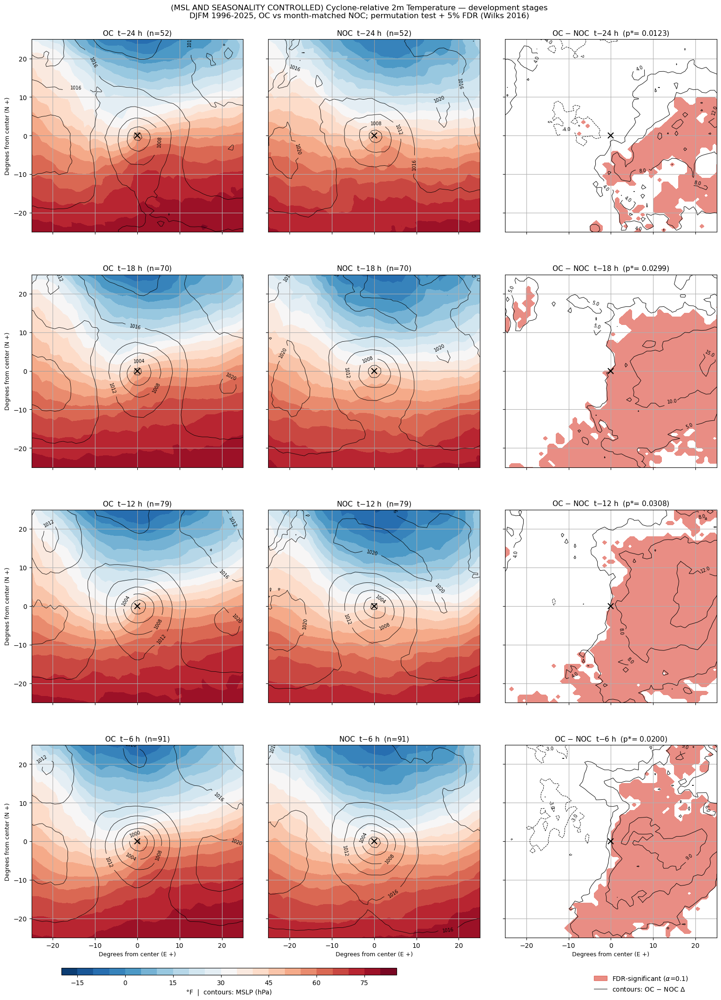

In [19]:
plot_dev(scalar("t2m", K2F), np.arange(-20, 86, 5), "RdBu_r", "°F  |  contours: MSLP (hPa)",
        "2m Temperature", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=0.0169, 984/5803 significant
t-18h  BH-FDR 0.1: p*=0.0249, 1494/5994 significant
t-12h  BH-FDR 0.1: p*=0.0290, 1744/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0216, 1287/5958 significant


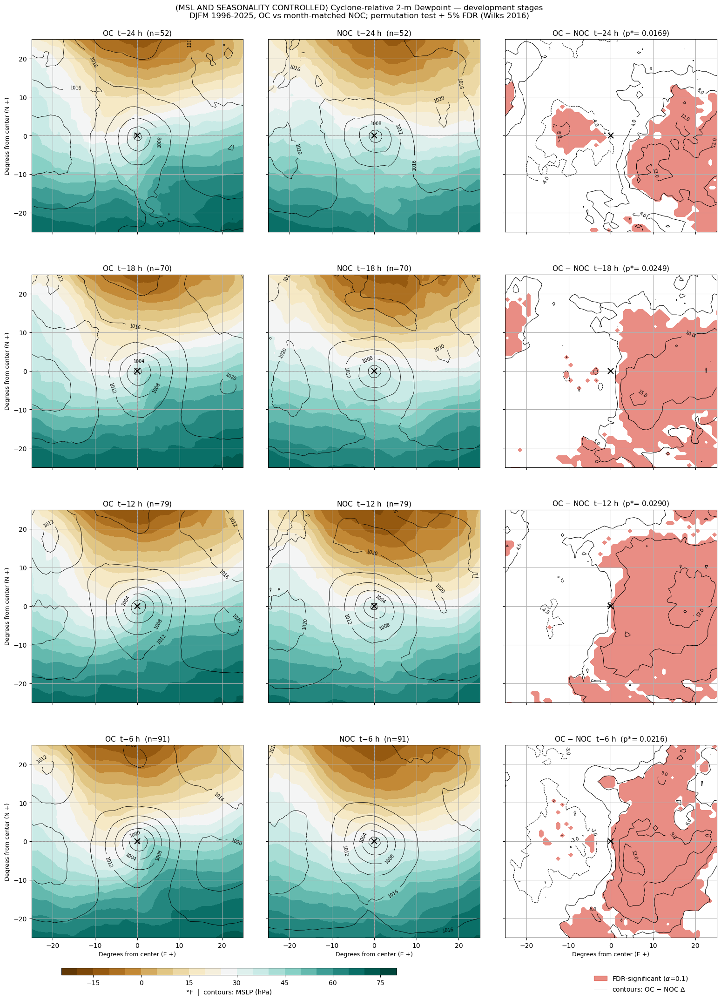

In [20]:
plot_dev(scalar("d2m", K2F), np.arange(-25, 81, 5), "BrBG", "°F  |  contours: MSLP (hPa)",
         "2-m Dewpoint", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5803 significant
t-18h  BH-FDR 0.1: p*=0.0044, 266/5994 significant
t-12h  BH-FDR 0.1: p*=0.0075, 452/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0084, 508/5958 significant


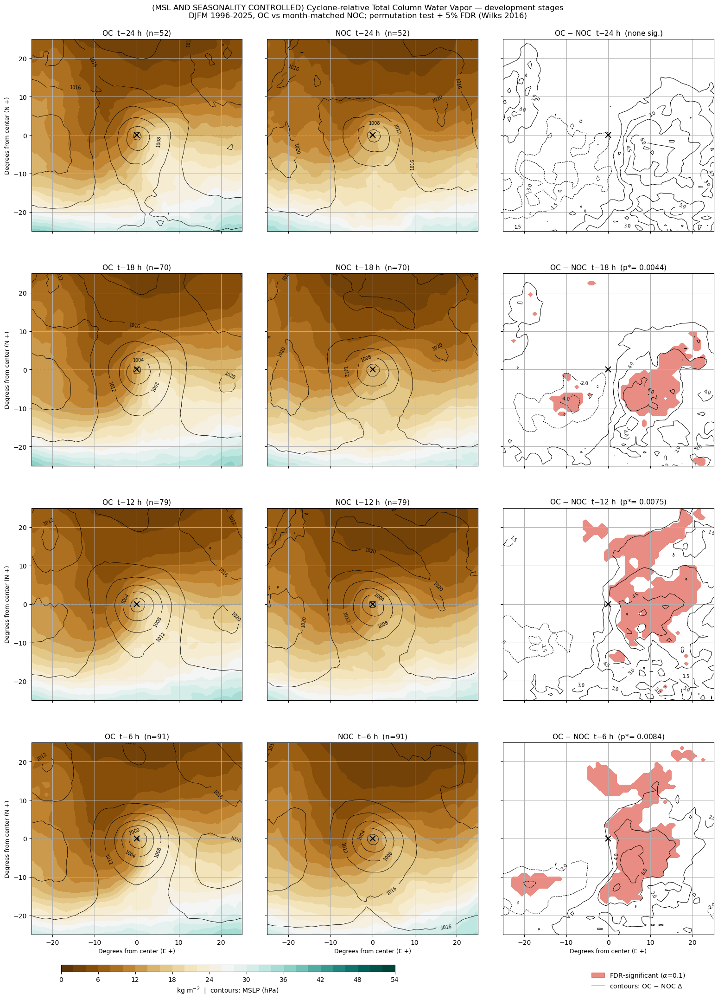

In [22]:
plot_dev(scalar("tcwv"), np.arange(0, 56, 2), "BrBG", "kg m$^{-2}$  |  contours: MSLP (hPa)",
         "Total Column Water Vapor", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5803 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5994 significant
t-12h  BH-FDR 0.1: p*=0.0001, 6/5986 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5958 significant


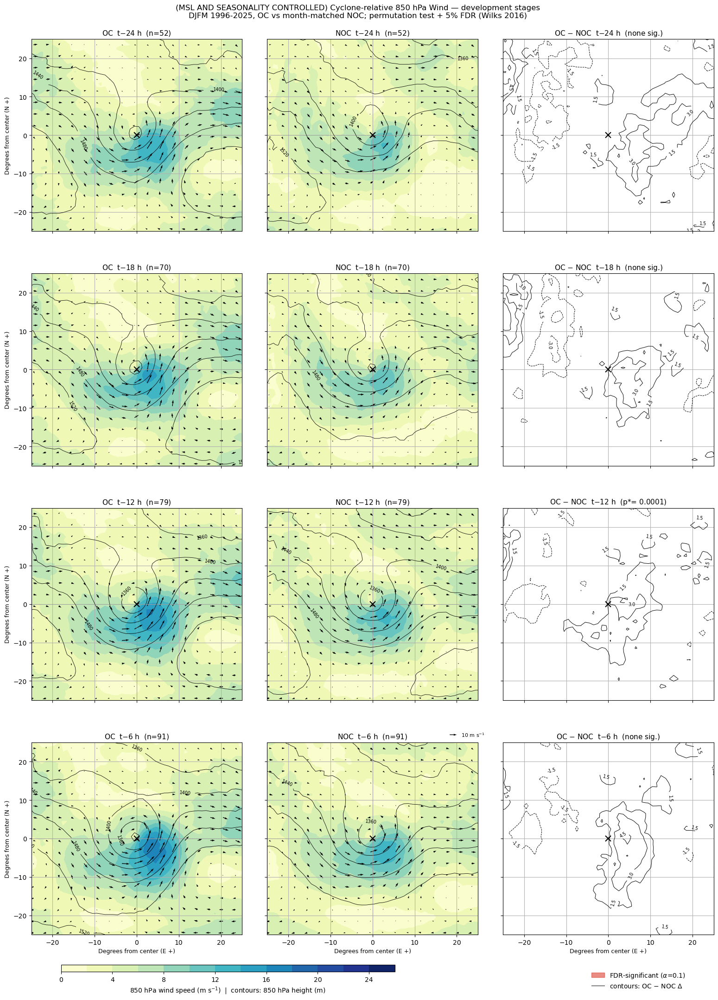

In [23]:
plot_dev(speed("u850", "v850"), np.arange(0, 27, 2), "YlGnBu",
         "850 hPa wind speed (m s$^{-1}$)  |  contours: 850 hPa height (m)",
         "850 hPa Wind", overlay=Z850_OV, vectors=("u850", "v850", 300))

t-24h  BH-FDR 0.1: p*=0.0022, 131/5803 significant
t-18h  BH-FDR 0.1: p*=0.0026, 156/5994 significant
t-12h  BH-FDR 0.1: p*=0.0031, 187/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0078, 467/5958 significant


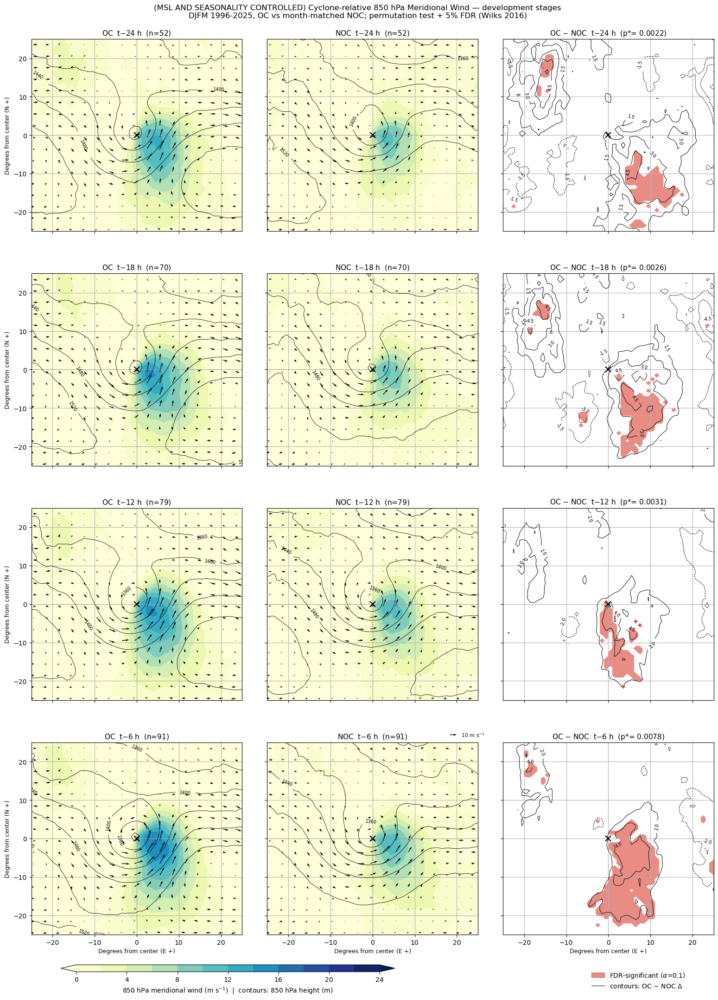

In [24]:
plot_dev(scalar("v850"), np.arange(0, 26, 2), "YlGnBu",
         "850 hPa meridional wind (m s$^{-1}$)  |  contours: 850 hPa height (m)",
         "850 hPa Meridional Wind", overlay=Z850_OV, vectors=("u850", "v850", 300), extend="both")

t-24h  BH-FDR 0.1: p*=nan, 0/5803 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5994 significant
t-12h  BH-FDR 0.1: p*=0.0234, 1403/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0077, 460/5958 significant


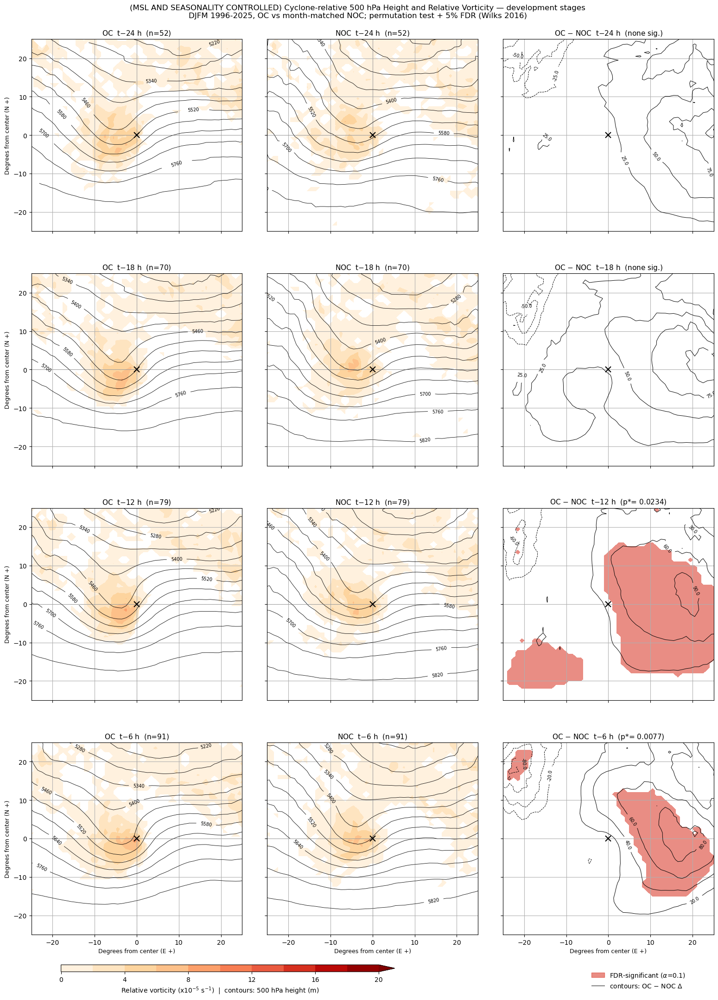

In [30]:
plot_dev(scalar("vo500", lambda a: a * 1e5), np.arange(0, 21, 2), "OrRd",
         "Relative vorticity (x10$^{-5}$ s$^{-1}$)  |  contours: 500 hPa height (m)",
         "500 hPa Height and Relative Vorticity", positive_only=True, extend="max",
         test=scalar("z500", lambda a: a / G), overlay=Z500_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5803 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5994 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5986 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5958 significant


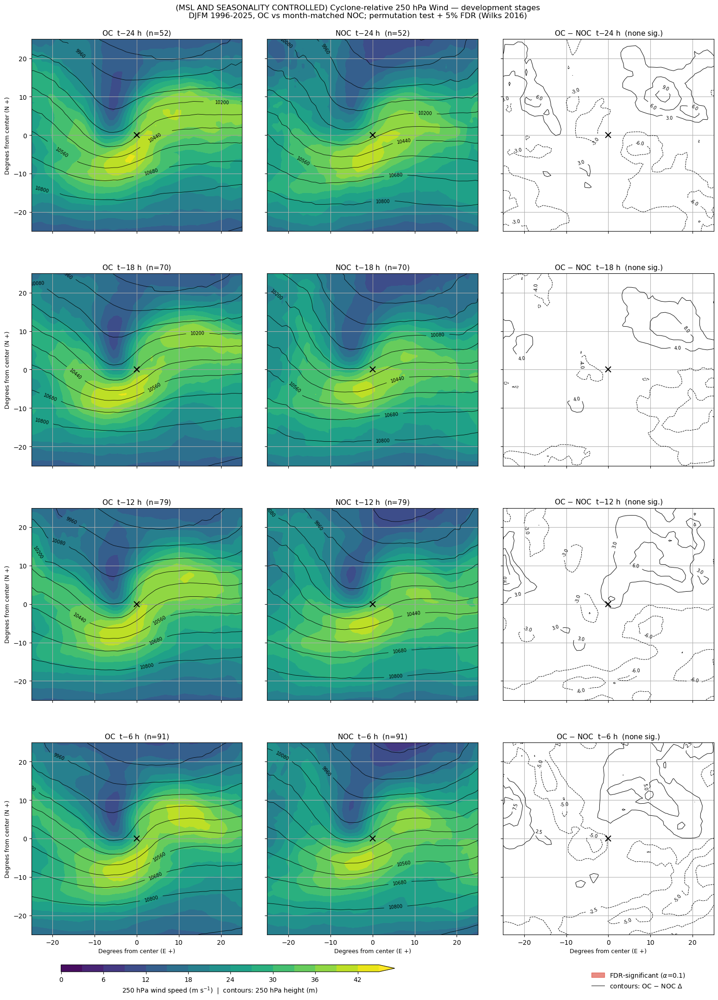

In [26]:
plot_dev(speed("u250", "v250"), np.arange(0, 46, 3), "viridis",
         "250 hPa wind speed (m s$^{-1}$)  |  contours: 250 hPa height (m)",
         "250 hPa Wind", overlay=Z250_OV, extend="max")

t-24h  BH-FDR 0.1: p*=0.0010, 61/5803 significant
t-18h  BH-FDR 0.1: p*=0.0028, 169/5994 significant
t-12h  BH-FDR 0.1: p*=0.0021, 127/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0028, 168/5958 significant


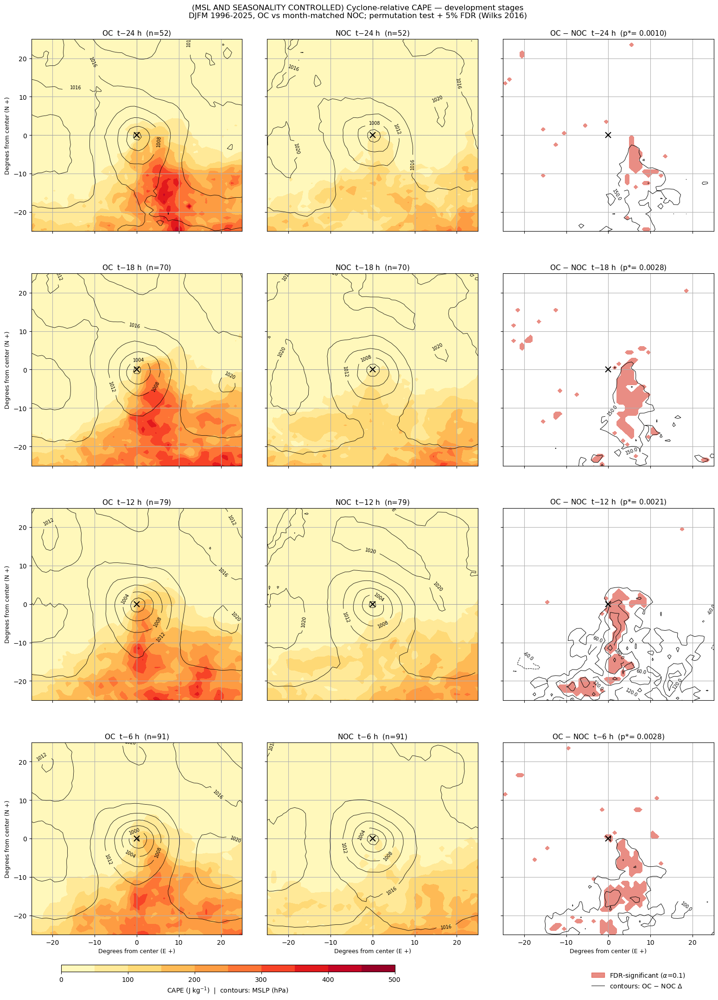

In [27]:
plot_dev(scalar("cape"), np.arange(0, 501, 50), "YlOrRd", "CAPE (J kg$^{-1}$)  |  contours: MSLP (hPa)",
         "CAPE", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5803 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5994 significant
t-12h  BH-FDR 0.1: p*=0.0027, 164/5986 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5958 significant


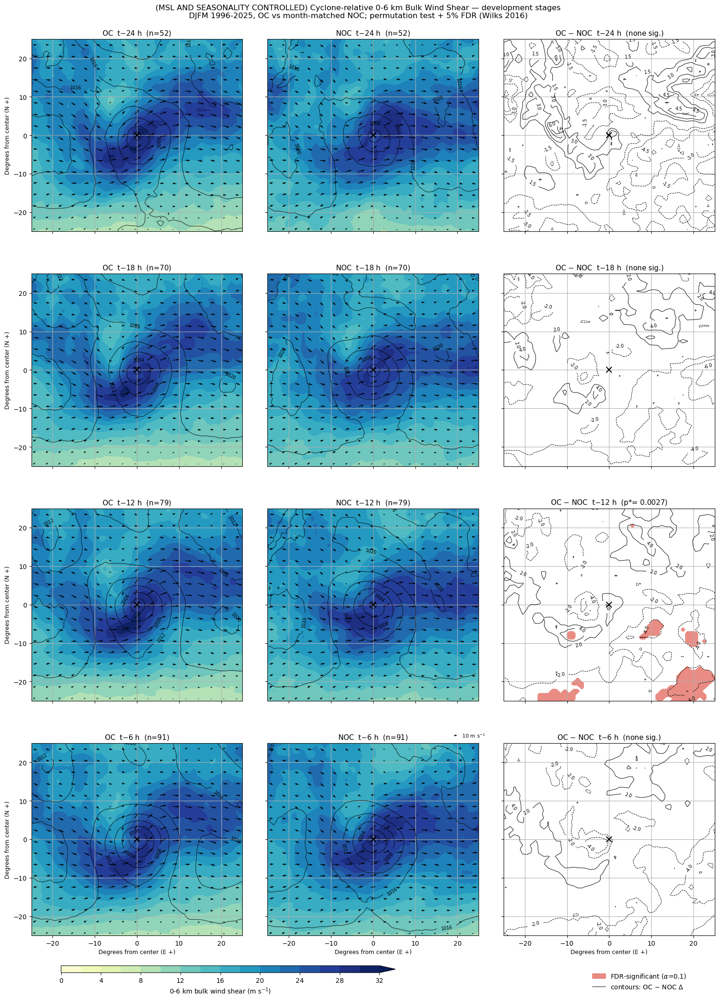

t-24h  BH-FDR 0.1: p*=nan, 0/5803 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5994 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0050, 298/5958 significant


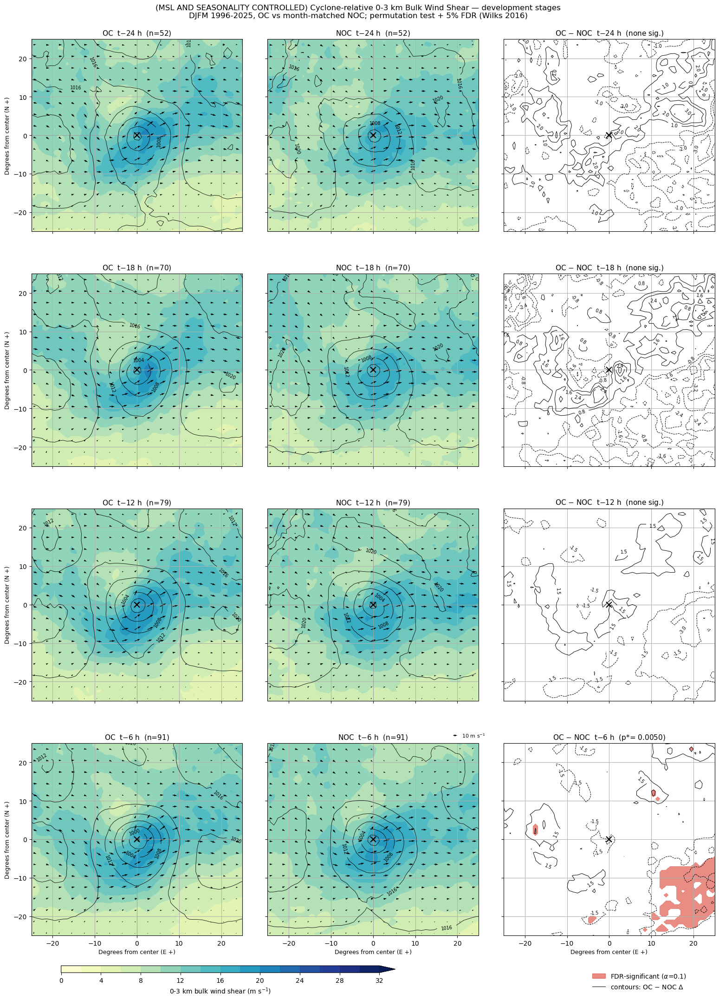

t-24h  BH-FDR 0.1: p*=0.0007, 45/5803 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5994 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5986 significant
t- 6h  BH-FDR 0.1: p*=0.0015, 90/5958 significant


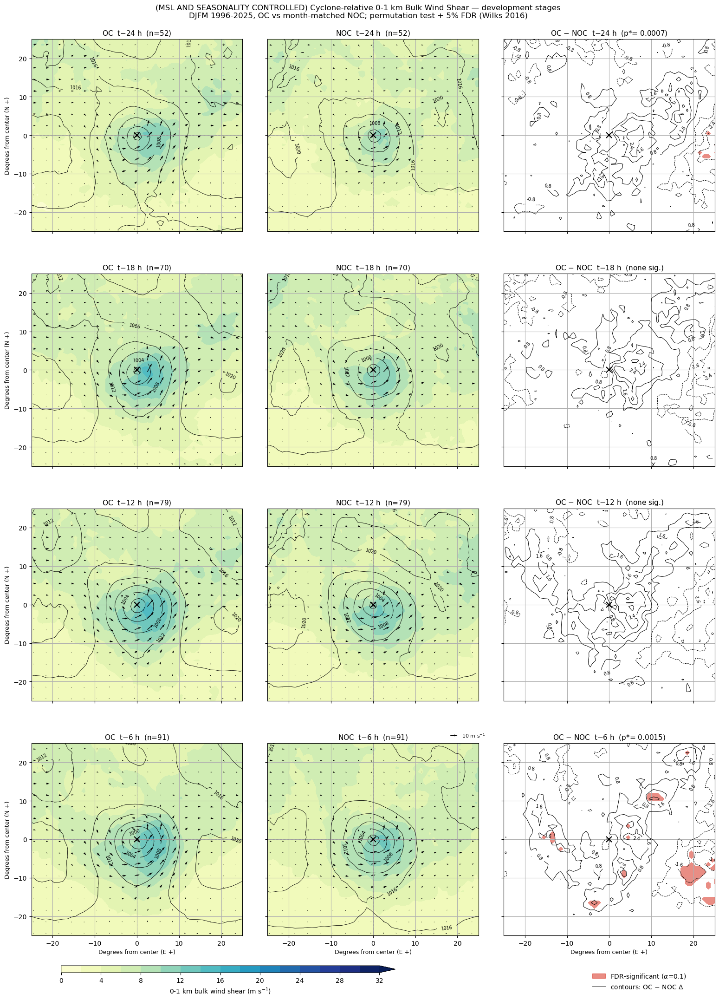

In [28]:
for tag, lbl, sc in (("shear06", "0-6 km", 700), ("shear03", "0-3 km", 500), ("shear01", "0-1 km", 300)):
    plot_dev(scalar(tag), np.arange(0, 33, 2), "YlGnBu", f"{lbl} bulk wind shear (m s$^{{-1}}$)",
             f"{lbl} Bulk Wind Shear", overlay=MSL_OV, vectors=(f"{tag}_u", f"{tag}_v", sc),
             extend="max", nbins=14)

## Plotting: -24, -18, -12, and -6 lags (SAME n of cyclones per lag time):

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=0.0197, 1144/5779 significant
t-12h  BH-FDR 0.1: p*=0.0202, 1159/5727 significant
t- 6h  BH-FDR 0.1: p*=0.0078, 447/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


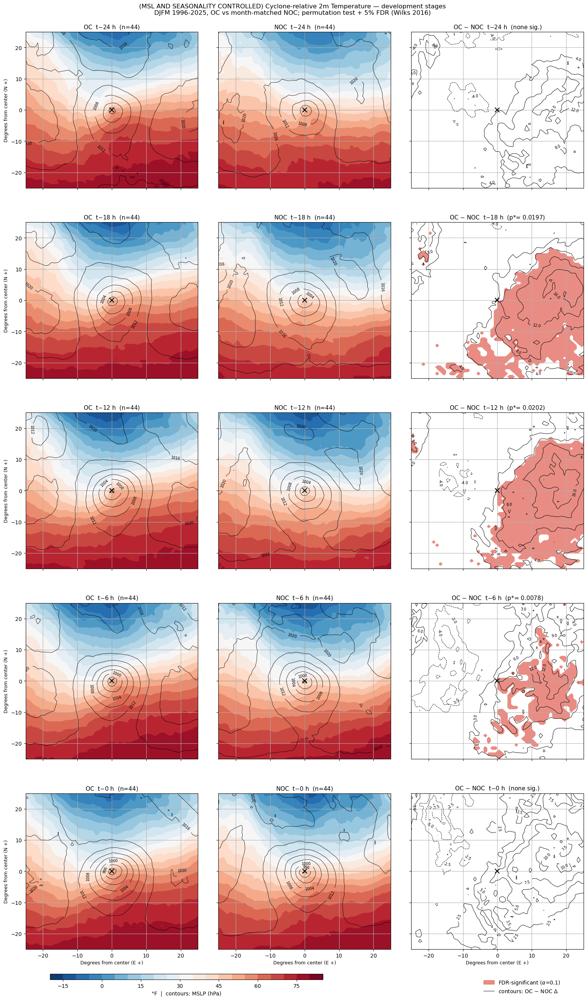

In [57]:
plot_dev(scalar("t2m", K2F), np.arange(-20, 86, 5), "RdBu_r", "°F  |  contours: MSLP (hPa)",
        "2m Temperature", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=0.0055, 316/5738 significant
t-18h  BH-FDR 0.1: p*=0.0154, 891/5779 significant
t-12h  BH-FDR 0.1: p*=0.0158, 905/5727 significant
t- 6h  BH-FDR 0.1: p*=0.0100, 573/5726 significant
t- 0h  BH-FDR 0.1: p*=0.0058, 332/5714 significant


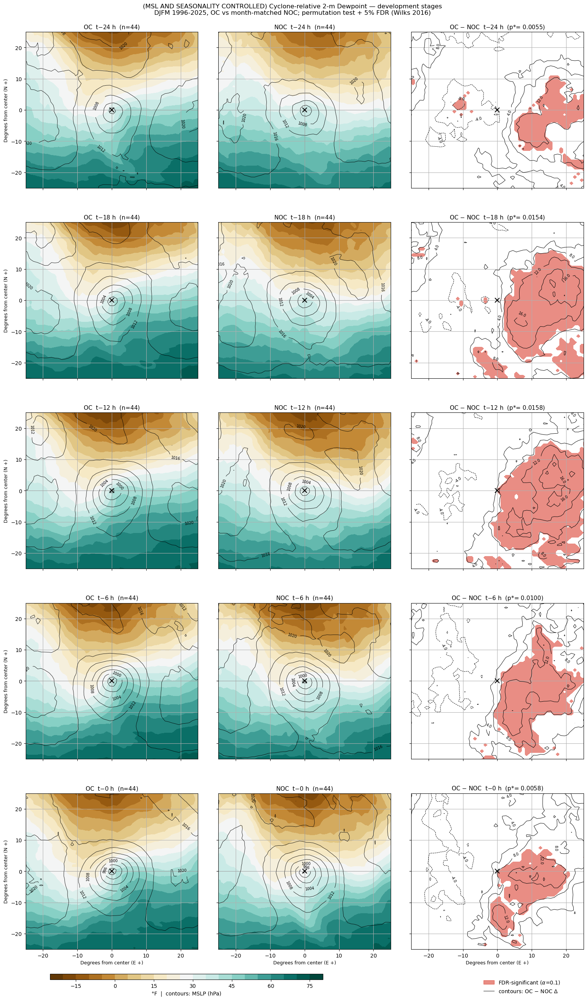

In [58]:
plot_dev(scalar("d2m", K2F), np.arange(-25, 81, 5), "BrBG", "°F  |  contours: MSLP (hPa)",
         "2-m Dewpoint", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=0.0066, 385/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=0.0037, 212/5726 significant
t- 0h  BH-FDR 0.1: p*=0.0035, 201/5714 significant


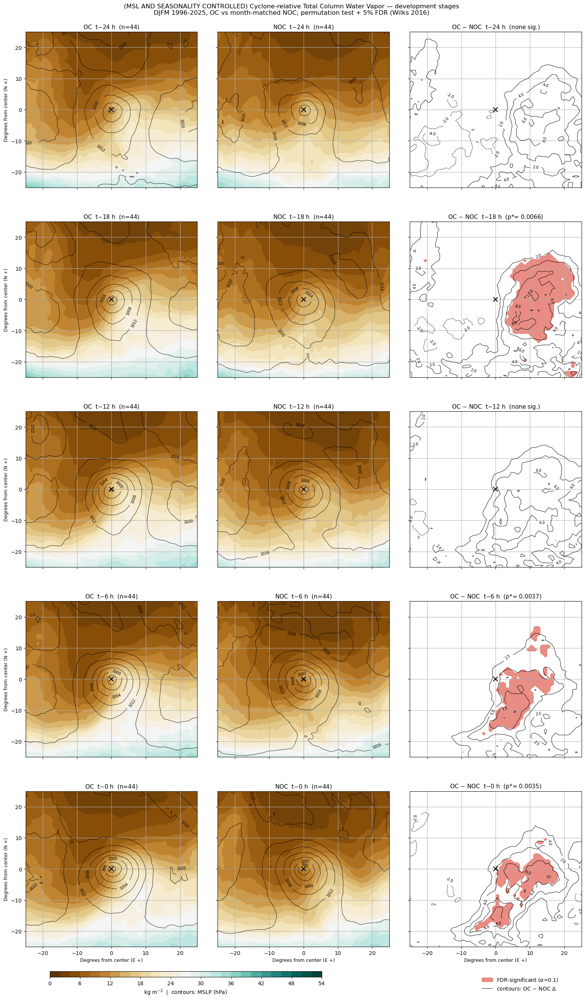

In [59]:
plot_dev(scalar("tcwv"), np.arange(0, 56, 2), "BrBG", "kg m$^{-2}$  |  contours: MSLP (hPa)",
         "Total Column Water Vapor", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=0.0001, 6/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


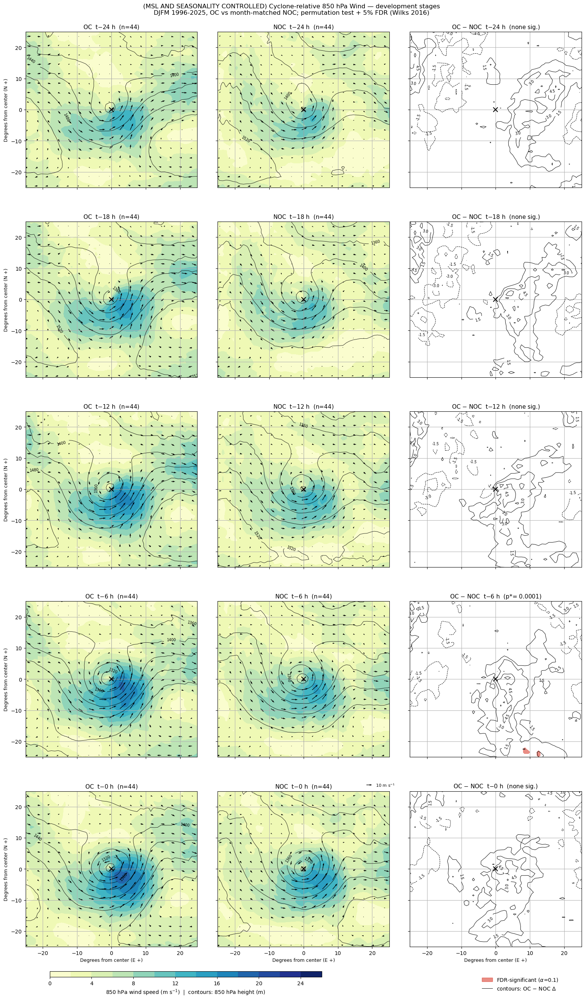

In [60]:
plot_dev(speed("u850", "v850"), np.arange(0, 27, 2), "YlGnBu",
         "850 hPa wind speed (m s$^{-1}$)  |  contours: 850 hPa height (m)",
         "850 hPa Wind", overlay=Z850_OV, vectors=("u850", "v850", 300))

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=0.0026, 152/5779 significant
t-12h  BH-FDR 0.1: p*=0.0022, 128/5727 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


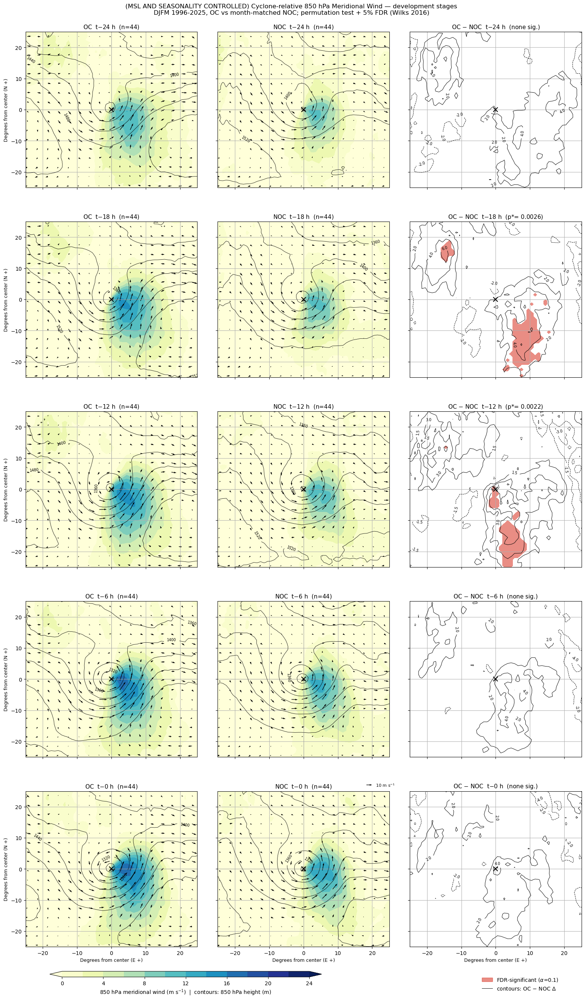

In [61]:
plot_dev(scalar("v850"), np.arange(0, 26, 2), "YlGnBu",
         "850 hPa meridional wind (m s$^{-1}$)  |  contours: 850 hPa height (m)",
         "850 hPa Meridional Wind", overlay=Z850_OV, vectors=("u850", "v850", 300), extend="both")

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


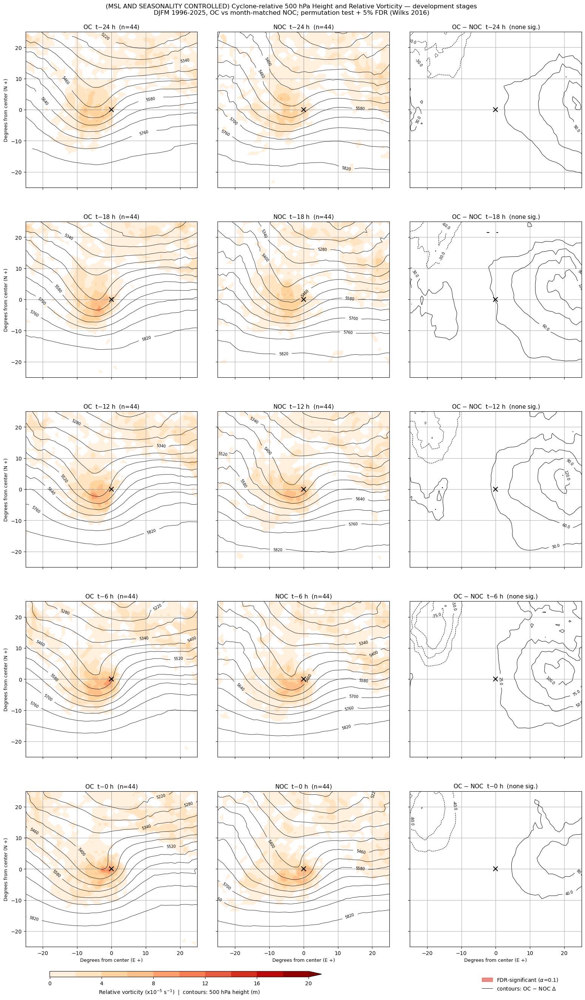

In [62]:
plot_dev(scalar("vo500", lambda a: a * 1e5), np.arange(0, 21, 2), "OrRd",
         "Relative vorticity (x10$^{-5}$ s$^{-1}$)  |  contours: 500 hPa height (m)",
         "500 hPa Height and Relative Vorticity", positive_only=True, extend="max",
         test=scalar("z500", lambda a: a / G), overlay=Z500_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


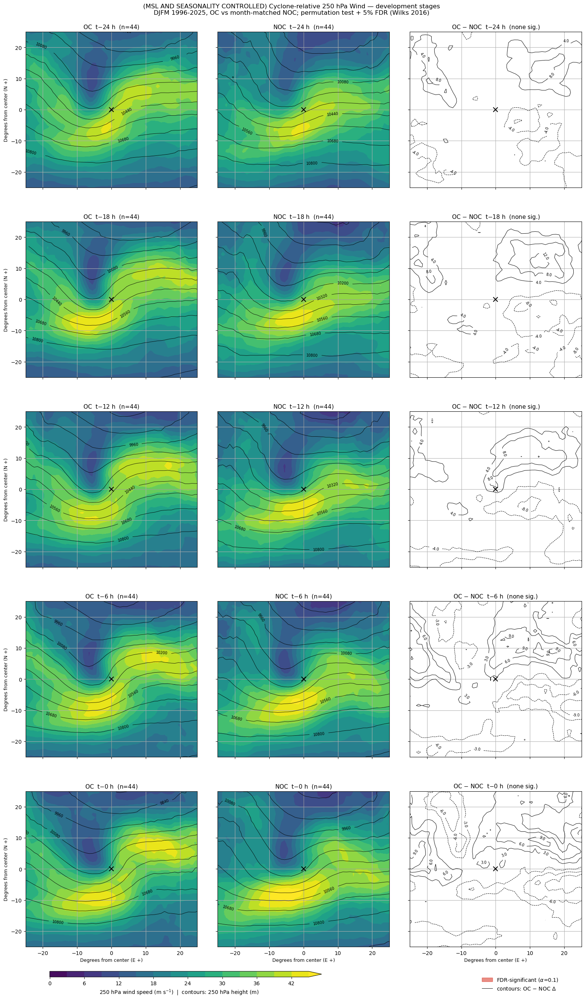

In [63]:
plot_dev(speed("u250", "v250"), np.arange(0, 46, 3), "viridis",
         "250 hPa wind speed (m s$^{-1}$)  |  contours: 250 hPa height (m)",
         "250 hPa Wind", overlay=Z250_OV, extend="max")

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=0.0029, 168/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


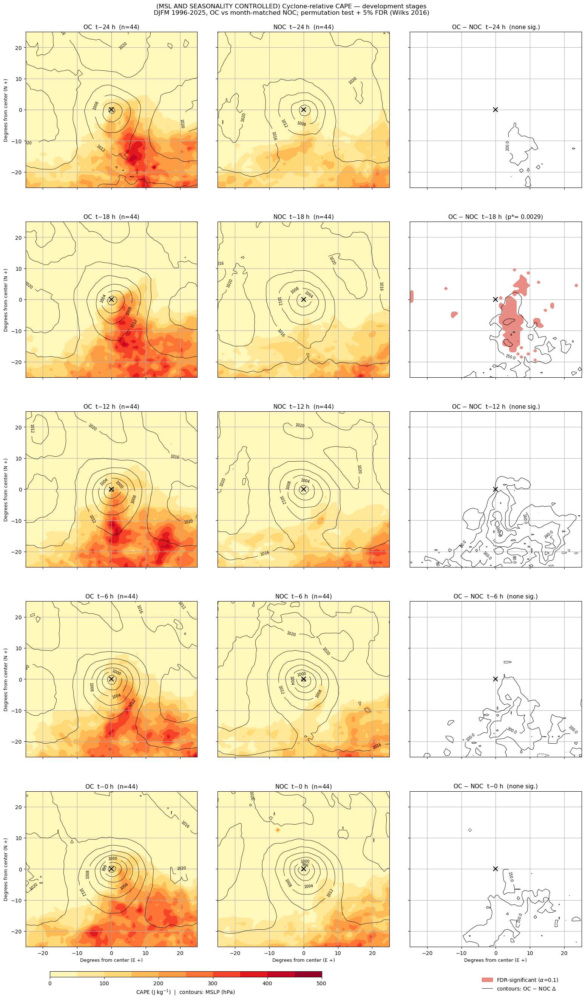

In [64]:
plot_dev(scalar("cape"), np.arange(0, 501, 50), "YlOrRd", "CAPE (J kg$^{-1}$)  |  contours: MSLP (hPa)",
         "CAPE", overlay=MSL_OV)

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


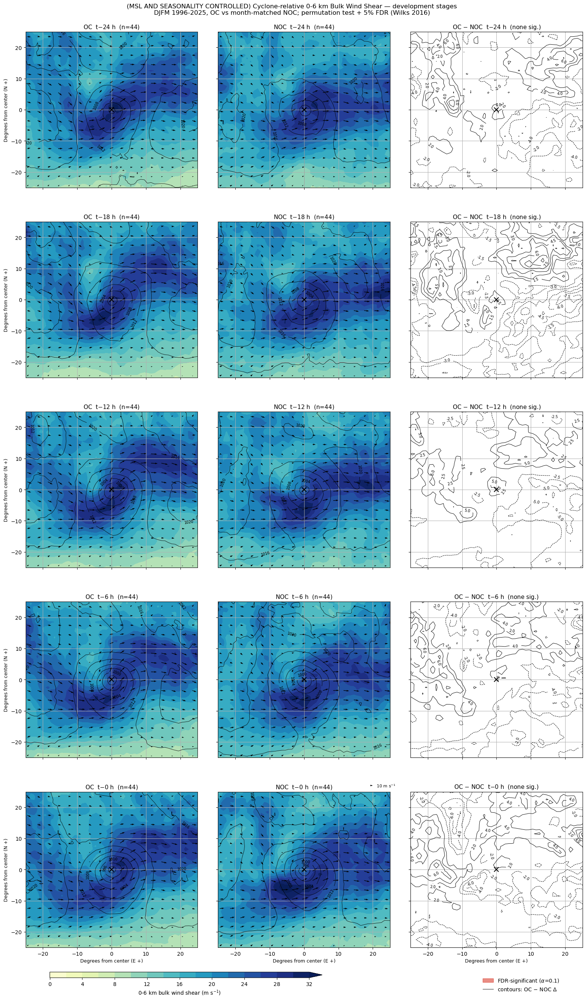

t-24h  BH-FDR 0.1: p*=0.0002, 13/5738 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5726 significant
t- 0h  BH-FDR 0.1: p*=0.0004, 23/5714 significant


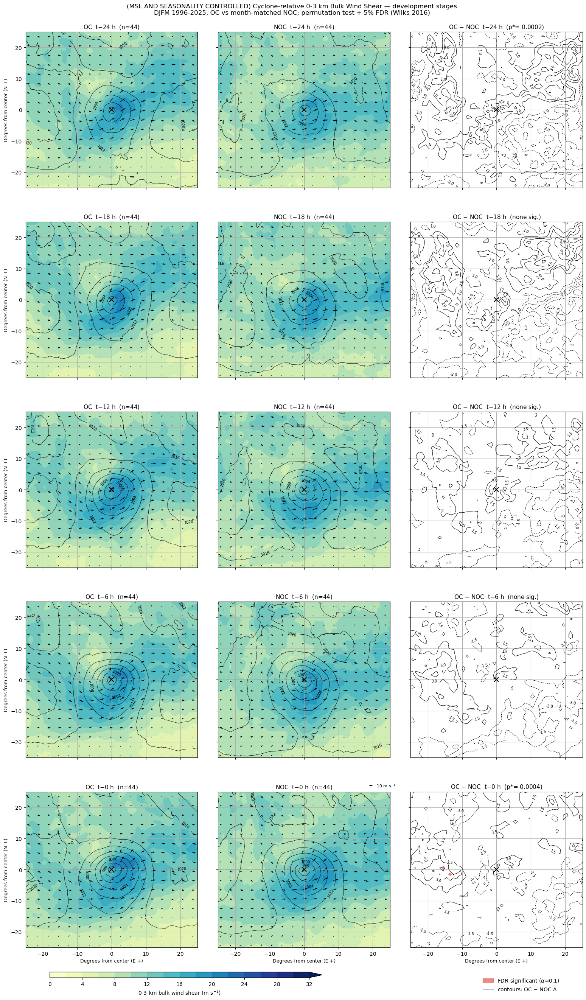

t-24h  BH-FDR 0.1: p*=nan, 0/5738 significant
t-18h  BH-FDR 0.1: p*=nan, 0/5779 significant
t-12h  BH-FDR 0.1: p*=nan, 0/5727 significant
t- 6h  BH-FDR 0.1: p*=nan, 0/5726 significant
t- 0h  BH-FDR 0.1: p*=nan, 0/5714 significant


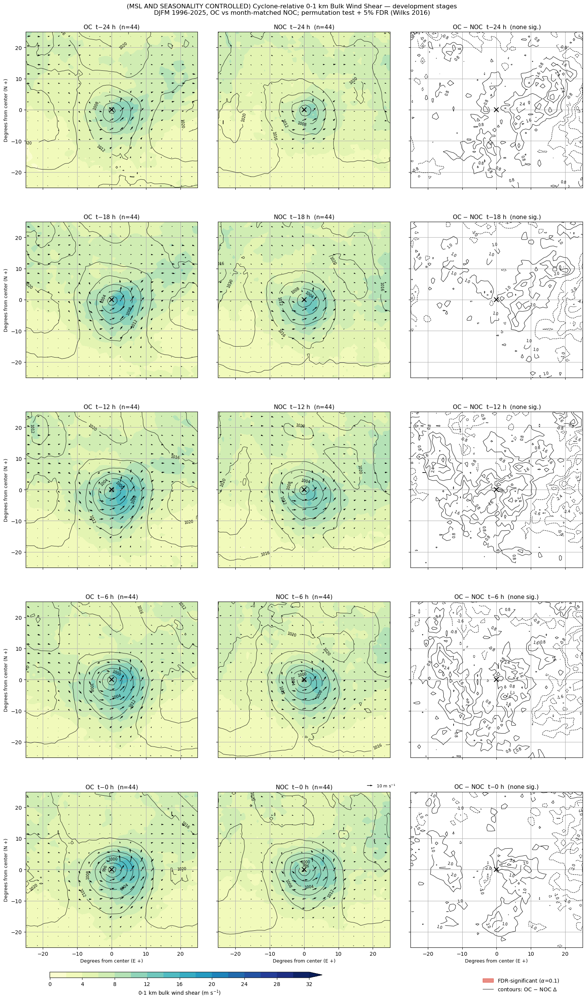

In [65]:
for tag, lbl, sc in (("shear06", "0-6 km", 700), ("shear03", "0-3 km", 500), ("shear01", "0-1 km", 300)):
    plot_dev(scalar(tag), np.arange(0, 33, 2), "YlGnBu", f"{lbl} bulk wind shear (m s$^{{-1}}$)",
             f"{lbl} Bulk Wind Shear", overlay=MSL_OV, vectors=(f"{tag}_u", f"{tag}_v", sc),
             extend="max", nbins=14)

## Creating nodefiles for the lag times of OCs relative to the first KDE core ONSET and PEAK times:

In [67]:
## First kept KDE core of every DJFM outbreak cyclone
cores = pd.read_csv("../data/kde_core_summary.csv")
cores = cores[cores["kept"]].copy()
for c in ("onset_time", "peak_time"):
    cores[c]  = pd.to_datetime(cores[c], utc=True)

## If a cyclone has more than one kept core, we only use the first one. 
first_core = (cores.sort_values("onset_time").groupby("track_id").head(1)
              .set_index("track_id")[["core_id", "onset_time", "peak_time", "n_reports"]])
first_core = first_core[first_core["onset_time"].dt.month.isin(MONTHS)
                        & first_core.index.isin(nodes_df["track_id"].unique())]
n_cores = cores.groupby("track_id").size().reindex(first_core.index)
print(f"{len(first_core)} DJFM cyclones with a kept core "
      f"({int((n_cores > 1).sum())} with >1 core -> earliest onset used)")
print("onset -> peak (h):",
      ((first_core["peak_time"] - first_core["onset_time"]) / pd.Timedelta("1h"))
      .describe()[["min", "50%", "max"]].to_dict())

270 DJFM cyclones with a kept core (58 with >1 core -> earliest onset used)
onset -> peak (h): {'min': 0.0, '50%': 6.0, 'max': 30.0}


In [68]:
## ---- cyclone center at ref - lag (same node_at() as the min-MSL lags) ----------
REFS = ["onset", "peak"]
LAGS = [24, 18, 12, 6, 0]            # hours BEFORE the first core's onset / peak

## node_at() reads the global `tracks` dict -- add the tracks it doesn't have yet
tracks.update({tid: g.sort_values("datetime").reset_index(drop=True)
               for tid, g in nodes_df[nodes_df["track_id"].isin(first_core.index)].groupby("track_id")
               if tid not in tracks})

rows = []
for tid, fc in first_core.iterrows():
    for ref in REFS:
        for lag in LAGS:
            t = fc[f"{ref}_time"] - pd.Timedelta(hours=lag)
            n = node_at(tid, t)
            base = {"track_id": tid, "ref": ref, "lag": lag, "target": t}
            rows.append({**n.to_dict(), **base, "available": True} if n is not None
                        else {**base, "available": False})
lag_nodes = pd.DataFrame(rows)

## Box filter at THIS composite's reference time: center at first-core onset
## must be inside CONUS_BOX (the min-MSL composites filtered at min MSL instead).
c0 = lag_nodes[(lag_nodes["ref"] == "onset") & (lag_nodes["lag"] == 0)
               & lag_nodes["available"]].set_index("track_id")
lon180 = ((c0["lon"] + 180) % 360) - 180
in_box = c0.index[lon180.between(CONUS_BOX[0], CONUS_BOX[1])
                  & c0["lat"].between(CONUS_BOX[2], CONUS_BOX[3])]
print(f"center at onset inside {CONUS_BOX}: {len(in_box)} / {len(first_core)} "
      f"({len(first_core) - len(c0)} have no node at onset)")
lag_nodes = lag_nodes[lag_nodes["track_id"].isin(in_box)].reset_index(drop=True)


center at onset inside [-125.0, -65.0, 25.0, 50.0]: 256 / 270 (0 have no node at onset)


In [69]:
## sample selection 
## FIXED_SAMPLE: per reference time, keep only cyclones with a node at EVERY lag,
## so all panels of one row are the same storms.
FIXED_SAMPLE = False

use = lag_nodes["available"]
if FIXED_SAMPLE:
    use &= lag_nodes.groupby(["track_id", "ref"])["available"].transform("all")
lag_sel = lag_nodes[use]

print(f"FIXED_SAMPLE={FIXED_SAMPLE}")
lon180 = ((lag_sel["lon"] + 180) % 360) - 180
summ = (lag_sel.assign(near_w=lon180 - 25 < ERA5_AREA[1])
        .groupby(["ref", "lag"])
        .agg(n=("track_id", "size"), interp=("interp", "sum"), near_w_edge=("near_w", "sum"),
             median_lat=("lat", "median"))
        .reindex(pd.MultiIndex.from_product([REFS, LAGS], names=["ref", "lag"])))
print(summ)


FIXED_SAMPLE=False
             n interp  near_w_edge  median_lat
ref   lag                                     
onset 24   148      6           14      39.875
      18   165      9            6      39.000
      12   181      6            6      38.500
      6    188     11            2      38.250
      0    256      0            1      37.750
peak  24   171      7            8      38.500
      18   186      8            3      38.250
      12   204     14            3      37.750
      6    226     15            1      38.250
      0    256      0            0      38.500


In [70]:
## ---- write nodefiles + the list of ERA5 hours they need ------------------------
LAG_NODEDIR = Path("../data/onset_peak_oc")
LAG_NODEDIR.mkdir(parents=True, exist_ok=True)

for ref in REFS:
    for lag in LAGS:
        sub = lag_sel[(lag_sel["ref"] == ref) & (lag_sel["lag"] == lag)].sort_values("track_id")
        write_snapshot_nodefile(sub, LAG_NODEDIR / f"oc_{ref}_m{lag:02d}h.txt", NODE_DATA_COLS)

## Every hour ANY available node needs (independent of FIXED_SAMPLE, so toggling
## it later never needs a second download). Input to download_era5_onset.py.
need = lag_nodes.loc[lag_nodes["available"], ["track_id", "ref", "lag", "datetime"]]
need.sort_values("datetime").to_csv(LAG_NODEDIR / "needed_times.csv", index=False)
print(f"needed_times.csv: {need['datetime'].nunique()} unique hours")

 wrote 148 -> ../data/onset_peak_oc/oc_onset_m24h.txt
 wrote 165 -> ../data/onset_peak_oc/oc_onset_m18h.txt
 wrote 181 -> ../data/onset_peak_oc/oc_onset_m12h.txt
 wrote 188 -> ../data/onset_peak_oc/oc_onset_m06h.txt
 wrote 256 -> ../data/onset_peak_oc/oc_onset_m00h.txt
 wrote 171 -> ../data/onset_peak_oc/oc_peak_m24h.txt
 wrote 186 -> ../data/onset_peak_oc/oc_peak_m18h.txt
 wrote 204 -> ../data/onset_peak_oc/oc_peak_m12h.txt
 wrote 226 -> ../data/onset_peak_oc/oc_peak_m06h.txt
 wrote 256 -> ../data/onset_peak_oc/oc_peak_m00h.txt
needed_times.csv: 1855 unique hours


In [71]:
etc = pd.read_csv("../data/etc_summary_final.csv")

In [73]:
etc.columns

Index(['track_id', 'track_start', 'track_end', 'time_min_msl', 'min_msl',
       'n_steps', 'n_reports', 'n_tornado', 'n_hail', 'n_wind',
       'n_cores_total', 'n_cores_kept', 'kept_reports', 'max_core_reports',
       'time_max_reports', 'ONI', 'MJO_min_msl', 'mjo_max_reports',
       'RI_winter_min_msl', 'RI_index_min_msl', 'RI_day_min_msl',
       'RI_day_10_min_msl', 'RI_index_10d_min_msl', 'RI_index_anom_min_msl',
       'days_since_RI_min_msl', 'RI_winter_max_reports',
       'RI_index_max_reports', 'RI_day_max_reports', 'RI_day_10_max_reports',
       'RI_index_10d_max_reports', 'RI_index_anom_max_reports',
       'days_since_RI_max_reports', 'snow_index', 'snow_index_reason',
       'significant_snow', 'snow_n_days', 'snow_area_T1_km2', 'snow_a_T1',
       'snow_area_T2_km2', 'snow_a_T2', 'snow_area_T3_km2', 'snow_a_T3',
       'snow_area_T4_km2', 'snow_a_T4', 'scs_outbreak', 'composite_group'],
      dtype='object')

In [82]:
cores = pd.read_csv("../data/kde_core_summary.csv")

In [83]:
cores

,track_id,core_id,n_reports,n_tornado,n_hail,n_wind,t_start,t_end,lat_min,lax_max,...,thr_density_ratio,kept,centroid_lat,centroid_lon,onset_time,peak_time,peak_n_reports,time_min_msl,onset_h_from_min_msl,peak_h_from_min_msl
0,25,25_1g0,271,23,32,216,1996-01-18 00:00:00+00:00,1996-01-19 02:00:00+00:00,30.250,43.3000,...,0.031657,True,36.166605,-91.123137,1996-01-18 00:00:00+00:00,1996-01-18 16:00:00+00:00,29,1996-01-21 00:00:00+00:00,-72.0,-56.0
1,25,25_1g1,85,1,1,83,1996-01-19 06:00:00+00:00,1996-01-19 22:00:00+00:00,34.620,43.7800,...,0.031657,True,38.142941,-77.120471,1996-01-19 06:00:00+00:00,1996-01-19 16:00:00+00:00,12,1996-01-21 00:00:00+00:00,-42.0,-32.0
2,28,28_0,50,2,13,35,1996-01-26 13:00:00+00:00,1996-01-27 12:00:00+00:00,30.230,34.3000,...,0.031657,True,31.963400,-87.189000,1996-01-26 13:00:00+00:00,1996-01-27 00:00:00+00:00,8,1996-01-20 02:00:00+00:00,155.0,166.0
3,54,54_1g2,84,0,64,20,1996-02-27 15:00:00+00:00,1996-02-28 02:00:00+00:00,32.120,40.5500,...,0.031657,True,35.580238,-91.026310,1996-02-27 15:00:00+00:00,1996-02-27 19:00:00+00:00,14,1996-03-01 09:00:00+00:00,-66.0,-62.0
4,60,60_1g0,171,11,107,53,1996-03-05 18:00:00+00:00,1996-03-06 12:00:00+00:00,29.830,38.3700,...,0.031657,True,34.999298,-91.348947,1996-03-05 18:00:00+00:00,1996-03-06 04:00:00+00:00,28,1996-03-04 23:00:00+00:00,19.0,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327,6109,6109_0g1,506,21,59,426,2025-03-16 03:00:00+00:00,2025-03-17 04:00:00+00:00,29.820,44.3300,...,0.040183,True,39.327536,-79.758995,2025-03-16 03:00:00+00:00,2025-03-16 16:00:00+00:00,134,2025-03-17 17:00:00+00:00,-38.0,-25.0
328,6111,6111_1,206,16,43,147,2025-03-19 07:00:00+00:00,2025-03-20 03:00:00+00:00,35.993,42.5300,...,0.040183,True,40.001778,-87.383061,2025-03-19 07:00:00+00:00,2025-03-19 21:00:00+00:00,42,2025-03-19 04:00:00+00:00,3.0,17.0
329,6113,6113_1,168,2,130,36,2025-03-23 21:00:00+00:00,2025-03-24 15:00:00+00:00,29.280,37.0739,...,0.040183,True,31.931806,-93.555014,2025-03-23 21:00:00+00:00,2025-03-23 23:00:00+00:00,35,2025-03-24 14:00:00+00:00,-17.0,-15.0
330,6117,6117_4g0,70,1,49,20,2025-03-30 00:00:00+00:00,2025-03-30 08:00:00+00:00,31.180,41.6000,...,0.040183,True,34.925389,-97.082104,2025-03-30 00:00:00+00:00,2025-03-30 02:00:00+00:00,19,2025-03-31 20:00:00+00:00,-44.0,-42.0


In [84]:
cores = cores.rename(columns={"lax_max":"lat_max"})

In [86]:
cores.to_csv("../data/kde_core_summary.csv")